# Delta‑V · Task 4
## Real outcome tables → scarce-data predictions → an honest GP reference

**Run all cells, from top to bottom. CPU only; no GPU, FNO checkpoint, account, or token is required.**
This notebook contains the exact small published outcome tables and source-inventory snapshots.
The embedded tables are real HF artifacts, not synthetic examples. Their SHA‑256 hashes are checked
before use. You may optionally re-download the same pinned artifacts from HF.

**The product question:** How accurately can we predict outcomes at unseen design settings from a few
completed settings? Task 4 creates the reusable data and reference benchmark for “bring your runs.”

**What runs:** data/schema audit; source-inventory expansion audit; locked grouped splits; mean, linear,
and Gaussian-process baselines; nested scarce-data budgets; interpolation and boundary tests;
uncertainty coverage and width; leakage/reproducibility checks; measured worked example; CSV/JSON,
figures, a written report, and a ZIP export.

**Scope:** These tables average sampled simulation windows at each parameter setting. Their rows are
**aggregated settings, not individual solver runs**. This is a retrospective setting-holdout pilot.
Original per-trajectory membership, sample counts, physical units, and aggregation variability are not
fully preserved. This notebook audits those gaps; it cannot reconstruct them from an NPZ.
No run-saving percentage or customer accuracy guarantee is inferred from this pilot.

### References, pinned where available
- [Delta‑V GitHub](https://github.com/krishoncloud/delta-v)
- [Track B source](https://github.com/krishoncloud/delta-v/blob/5645c6ec675e466649bc9e35a8da92848f3a60bd/research/track_b.py)
- [Published artifacts](https://huggingface.co/datasets/KrishMalik/deltav-fluid/tree/e25651ff92cf1d8f8818164a0277b8613e83d8b3)
- [Historical Track B results](https://huggingface.co/datasets/KrishMalik/deltav-fluid/blob/e25651ff92cf1d8f8818164a0277b8613e83d8b3/research/design-runs-track-b/v1/results.json)
- [Euler Track A summary](https://huggingface.co/datasets/KrishMalik/deltav-fluid/blob/e25651ff92cf1d8f8818164a0277b8613e83d8b3/research/euler-track-a/v3/summary/summary.json)

This is a new task-4 protocol, not a reproduction or replacement of historical Track B. Euler's field
transfer result remains separate. No pretrained model is evaluated here.

### 1 · Dependencies
The cell installs only missing packages. Existing environments are preserved and their exact versions
are saved in the report. The listed versions were used to validate this notebook. On a clean Python
3.11–3.13 kernel they can also be installed explicitly for closer reproduction. Internet is needed only
for missing packages or the optional HF refresh. No repository code is downloaded or executed.

In [1]:
import os, sys, subprocess, importlib.util
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".task4-matplotlib"))
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
PACKAGES = {"numpy": "numpy==2.1.2", "scipy": "scipy==1.14.1",
            "pandas": "pandas==2.2.3", "sklearn": "scikit-learn==1.8.0",
            "matplotlib": "matplotlib==3.9.2", "threadpoolctl": "threadpoolctl==3.6.0"}
missing = [spec for module, spec in PACKAGES.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import base64, hashlib, io, json, platform, re, shutil, time, warnings
from datetime import datetime, timezone
from statistics import NormalDist
import numpy as np
import pandas as pd
import scipy
from scipy.spatial import ConvexHull
import sklearn
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.linear_model import Ridge
import matplotlib
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown, FileLink

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__,
            "scipy": scipy.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}
print(VERSIONS)

Matplotlib is building the font cache; this may take a moment.


{'python': '3.13.0', 'numpy': '2.1.2', 'scipy': '1.14.1', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.9.2'}


### 2 · Your design controls — edit before running
Defaults run all three systems with three fixed seeds, common nested training selections, and all tests.
The GP uses one training-only optimization start by default; increase `GP_RESTARTS` **before** comparing
results, rather than picking it after looking at test errors. The kernel family and all choices are fixed
in advance. Every run creates a new output directory.

`ACCURACY_TOLERANCES` is empty because no customer has supplied an engineering tolerance. To enable the
optional target analysis, supply a positive **RMSE tolerance in stored outcome units for both outcomes**
of a system. That is a retrospective diagnostic, not an automatic stopping rule or proof of saved runs.

In [2]:
HF_REPO = "KrishMalik/deltav-fluid"
HF_REVISION = "e25651ff92cf1d8f8818164a0277b8613e83d8b3"
GITHUB_REVISION = "5645c6ec675e466649bc9e35a8da92848f3a60bd"
SYSTEMS = ["turbulent_radiative_layer_2D", "rayleigh_benard", "shear_flow"]
INPUTS = {"turbulent_radiative_layer_2D": ["t_cool"],
          "rayleigh_benard": ["rayleigh_number", "prandtl"],
          "shear_flow": ["reynolds", "schmidt"]}
OUTCOMES = ["mass_flux", "turbulent_velocity"]
SEEDS = [42, 123, 2026]
REQUESTED_BUDGETS = [3, 4, 6, 8, 12, 16, 24]
TEST_FRACTION = 0.20
GP_RESTARTS = 0
REFRESH_TABLES_FROM_HF = False
ACCURACY_TOLERANCES = {}  # e.g. {system: {outcome: positive_absolute_rmse_tolerance, ...}}
OUTPUT_ROOT = Path("delta_v_task4_results")
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR = OUTPUT_ROOT / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
for folder in ("data", "sources", "figures"):
    (RUN_DIR / folder).mkdir()

def digest(blob):
    return hashlib.sha256(blob).hexdigest()

def save_json(path, obj):
    Path(path).write_text(json.dumps(obj, indent=2, sort_keys=True, allow_nan=False) + "\n")

def save_csv(frame, path):
    frame.to_csv(path, index=False, float_format="%.17g")

assert len(SEEDS) == len(set(SEEDS)) and len(SEEDS) >= 1
assert 0 < TEST_FRACTION < 0.5 and GP_RESTARTS >= 0
assert REQUESTED_BUDGETS and min(REQUESTED_BUDGETS) >= 3
for system, tolerances in ACCURACY_TOLERANCES.items():
    assert system in SYSTEMS and set(tolerances) == set(OUTCOMES)
    assert all(np.isfinite(v) and v > 0 for v in tolerances.values())
print("Results directory:", RUN_DIR.resolve())

Results directory: ./delta_v_task4_results/20261015T171126_203958Z


### 3 · Exact artifact snapshot
The following collapsed cell contains only data and metadata. The three NPZs total less than 6 KB.
Source inventories contain filenames, not simulation fields. HF source revisions below are from the
repository's existing source probe; matching filenames **does not establish the original table's exact
source revision or per-trajectory lineage**.

In [3]:
SNAPSHOT = {'turbulent_radiative_layer_2D': {'npz_base64': 'UEsDBC0AAAAAAAAAIQARRDve//////////8KABQAcG9pbnRzLm5weQEAEADIAAAAAAAAAMgAAAAAAAAAk05VTVBZAQB2AHsnZGVzY3InOiAnPGY4JywgJ2ZvcnRyYW5fb3JkZXInOiBGYWxzZSwgJ3NoYXBlJzogKDksIDEpLCB9ICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIAoAAADgUbiePwAAAOBRuK4/AAAAoJmZuT8AAACAPQrHPwAAAEDhetQ/AAAAIIXr4T8AAAAAAADwPwAAAEDhevw/AAAAIK5HCUBQSwMELQAAAAAAAAAhAJbgz4H//////////woAFAB2YWx1ZXMubnB5AQAQABABAAAAAAAAEAEAAAAAAACTTlVNUFkBAHYAeydkZXNjcic6ICc8ZjgnLCAnZm9ydHJhbl9vcmRlcic6IEZhbHNlLCAnc2hhcGUnOiAoOSwgMiksIH0gICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgCshCFlcA/qG/hixkiXhWsz8AAFD+x5Cmv2QhCzlKMLE/bMEWUxAZlb9Q+qQvR9SsP9/0po0RDoC/WchCRjTiqT/1pvcL2Ft/vwAAAIBZYac/juMYKcUKgr/kOI6DtP6lPzi96R8GnlI/etObLu4npT/f9Ka3b40vv5ze9MZhoKQ/zczM5APTgD+O4ziOe4CkP1BLAwQtAAAAAAAAACEAiefdvP//////////EAAUAG1ldHJpY19uYW1lcy5ucHkBABAAEAEAAAAAAAAQAQAAAAAAAJNOVU1QWQEAdgB7J2Rlc2NyJzogJzxVMTgnLCAnZm9ydHJhbl9vcmRlcic6IEZhbHNlLCAnc2hhcGUnOiAoMiwpLCB9ICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAKbQAAAGEAAABzAAAAcwAAAF8AAABmAAAAbAAAAHUAAAB4AAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAdAAAAHUAAAByAAAAYgAAAHUAAABsAAAAZQAAAG4AAAB0AAAAXwAAAHYAAABlAAAAbAAAAG8AAABjAAAAaQAAAHQAAAB5AAAAUEsDBC0AAAAAAAAAIQBx2cVG//////////8OABQAZGlhbF9uYW1lcy5ucHkBABAAmAAAAAAAAACYAAAAAAAAAJNOVU1QWQEAdgB7J2Rlc2NyJzogJzxVNicsICdmb3J0cmFuX29yZGVyJzogRmFsc2UsICdzaGFwZSc6ICgxLCksIH0gICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAKdAAAAF8AAABjAAAAbwAAAG8AAABsAAAAUEsBAi0DLQAAAAAAAAAhABFEO97IAAAAyAAAAAoAAAAAAAAAAAAAAIABAAAAAHBvaW50cy5ucHlQSwECLQMtAAAAAAAAACEAluDPgRABAAAQAQAACgAAAAAAAAAAAAAAgAEEAQAAdmFsdWVzLm5weVBLAQItAy0AAAAAAAAAIQCJ5928EAEAABABAAAQAAAAAAAAAAAAAACAAVACAABtZXRyaWNfbmFtZXMubnB5UEsBAi0DLQAAAAAAAAAhAHHZxUaYAAAAmAAAAA4AAAAAAAAAAAAAAIABogMAAGRpYWxfbmFtZXMubnB5UEsFBgAAAAAEAAQA6gAAAHoEAAAAAA==', 'sha256': '3e068d1cef27941eedd29c7f9289789d171687ab44fd5e4d530030f9e48f009d', 'size_bytes': 1402, 'source_inventory': {'_id': '674f945a224ca9cc908c343b', 'id': 'polymathic-ai/turbulent_radiative_layer_2D', 'author': 'polymathic-ai', 'sha': '2ee7756575ff6f90981d0308cbcb6a2ab5995bdc', 'lastModified': '2025-04-10T07:50:21.000Z', 'private': False, 'gated': False, 'disabled': False, 'tags': ['task_categories:time-series-forecasting', 'task_categories:other', 'task_ids:multivariate-time-series-forecasting', 'language:en', 'license:cc-by-4.0', 'region:us', 'physics'], 'description': '\n\t\n\t\t\n\t\n\t\n\t\tHow To Load from HuggingFace Hub\n\t\n\n\nBe sure to have the_well installed (pip install the_well)\nUse the WellDataModule to retrieve data as follows:\n\nfrom the_well.data import WellDataModule\n\n# The following line may take a couple of minutes to instantiate the datamodule\ndatamodule = WellDataModule(\n    "hf://datasets/polymathic-ai/",\n    "turbulent_radiative_layer_2D",\n)\ntrain_dataloader = datamodule.train_dataloader()\n\nfor batch in dataloader:\n    # Process training batch\n    ...… See the full description on the dataset page: https://huggingface.co/datasets/polymathic-ai/turbulent_radiative_layer_2D.', 'downloads': 1365, 'likes': 3, 'cardData': {'language': ['en'], 'license': 'cc-by-4.0', 'tags': ['physics'], 'task_categories': ['time-series-forecasting', 'other'], 'task_ids': ['multivariate-time-series-forecasting']}, 'siblings': [{'rfilename': '.gitattributes'}, {'rfilename': 'README.md'}, {'rfilename': 'data/test/turbulent_radiative_layer_tcool_0.03.hdf5'}, {'rfilename': 'data/test/turbulent_radiative_layer_tcool_0.06.hdf5'}, {'rfilename': 'data/test/turbulent_radiative_layer_tcool_0.10.hdf5'}, {'rfilename': 'data/test/turbulent_radiative_layer_tcool_0.18.hdf5'}, {'rfilename': 'data/test/turbulent_radiative_layer_tcool_0.32.hdf5'}, {'rfilename': 'data/test/turbulent_radiative_layer_tcool_0.56.hdf5'}, {'rfilename': 'data/test/turbulent_radiative_layer_tcool_1.00.hdf5'}, {'rfilename': 'data/test/turbulent_radiative_layer_tcool_1.78.hdf5'}, {'rfilename': 'data/test/turbulent_radiative_layer_tcool_3.16.hdf5'}, {'rfilename': 'data/train/turbulent_radiative_layer_tcool_0.03.hdf5'}, {'rfilename': 'data/train/turbulent_radiative_layer_tcool_0.06.hdf5'}, {'rfilename': 'data/train/turbulent_radiative_layer_tcool_0.10.hdf5'}, {'rfilename': 'data/train/turbulent_radiative_layer_tcool_0.18.hdf5'}, {'rfilename': 'data/train/turbulent_radiative_layer_tcool_0.32.hdf5'}, {'rfilename': 'data/train/turbulent_radiative_layer_tcool_0.56.hdf5'}, {'rfilename': 'data/train/turbulent_radiative_layer_tcool_1.00.hdf5'}, {'rfilename': 'data/train/turbulent_radiative_layer_tcool_1.78.hdf5'}, {'rfilename': 'data/train/turbulent_radiative_layer_tcool_3.16.hdf5'}, {'rfilename': 'data/valid/turbulent_radiative_layer_tcool_0.03.hdf5'}, {'rfilename': 'data/valid/turbulent_radiative_layer_tcool_0.06.hdf5'}, {'rfilename': 'data/valid/turbulent_radiative_layer_tcool_0.10.hdf5'}, {'rfilename': 'data/valid/turbulent_radiative_layer_tcool_0.18.hdf5'}, {'rfilename': 'data/valid/turbulent_radiative_layer_tcool_0.32.hdf5'}, {'rfilename': 'data/valid/turbulent_radiative_layer_tcool_0.56.hdf5'}, {'rfilename': 'data/valid/turbulent_radiative_layer_tcool_1.00.hdf5'}, {'rfilename': 'data/valid/turbulent_radiative_layer_tcool_1.78.hdf5'}, {'rfilename': 'data/valid/turbulent_radiative_layer_tcool_3.16.hdf5'}, {'rfilename': 'gif/density_normalized.gif'}, {'rfilename': 'gif/density_unnormalized.gif'}, {'rfilename': 'stats.yaml'}, {'rfilename': 'turbulent_radiative_layer_2D.yaml'}, {'rfilename': 'visualization_turbulent_radiative_layer_2D.ipynb'}], 'createdAt': '2024-12-03T23:29:30.000Z', 'usedStorage': 7856083849}, 'source_inventory_sha256': '55eab7dcc0f7f569db08a602868238000caa1272eb3950914bff9d4b41f54ad1', 'source_inventory_base64': 'eyJfaWQiOiI2NzRmOTQ1YTIyNGNhOWNjOTA4YzM0M2IiLCJpZCI6InBvbHltYXRoaWMtYWkvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl8yRCIsImF1dGhvciI6InBvbHltYXRoaWMtYWkiLCJzaGEiOiIyZWU3NzU2NTc1ZmY2ZjkwOTgxZDAzMDhjYmNiNmEyYWI1OTk1YmRjIiwibGFzdE1vZGlmaWVkIjoiMjAyNS0wNC0xMFQwNzo1MDoyMS4wMDBaIiwicHJpdmF0ZSI6ZmFsc2UsImdhdGVkIjpmYWxzZSwiZGlzYWJsZWQiOmZhbHNlLCJ0YWdzIjpbInRhc2tfY2F0ZWdvcmllczp0aW1lLXNlcmllcy1mb3JlY2FzdGluZyIsInRhc2tfY2F0ZWdvcmllczpvdGhlciIsInRhc2tfaWRzOm11bHRpdmFyaWF0ZS10aW1lLXNlcmllcy1mb3JlY2FzdGluZyIsImxhbmd1YWdlOmVuIiwibGljZW5zZTpjYy1ieS00LjAiLCJyZWdpb246dXMiLCJwaHlzaWNzIl0sImRlc2NyaXB0aW9uIjoiXG5cdFxuXHRcdFxuXHRcblx0XG5cdFx0SG93IFRvIExvYWQgZnJvbSBIdWdnaW5nRmFjZSBIdWJcblx0XG5cblxuQmUgc3VyZSB0byBoYXZlIHRoZV93ZWxsIGluc3RhbGxlZCAocGlwIGluc3RhbGwgdGhlX3dlbGwpXG5Vc2UgdGhlIFdlbGxEYXRhTW9kdWxlIHRvIHJldHJpZXZlIGRhdGEgYXMgZm9sbG93czpcblxuZnJvbSB0aGVfd2VsbC5kYXRhIGltcG9ydCBXZWxsRGF0YU1vZHVsZVxuXG4jIFRoZSBmb2xsb3dpbmcgbGluZSBtYXkgdGFrZSBhIGNvdXBsZSBvZiBtaW51dGVzIHRvIGluc3RhbnRpYXRlIHRoZSBkYXRhbW9kdWxlXG5kYXRhbW9kdWxlID0gV2VsbERhdGFNb2R1bGUoXG4gICAgXCJoZjovL2RhdGFzZXRzL3BvbHltYXRoaWMtYWkvXCIsXG4gICAgXCJ0dXJidWxlbnRfcmFkaWF0aXZlX2xheWVyXzJEXCIsXG4pXG50cmFpbl9kYXRhbG9hZGVyID0gZGF0YW1vZHVsZS50cmFpbl9kYXRhbG9hZGVyKClcblxuZm9yIGJhdGNoIGluIGRhdGFsb2FkZXI6XG4gICAgIyBQcm9jZXNzIHRyYWluaW5nIGJhdGNoXG4gICAgLi4u4oCmIFNlZSB0aGUgZnVsbCBkZXNjcmlwdGlvbiBvbiB0aGUgZGF0YXNldCBwYWdlOiBodHRwczovL2h1Z2dpbmdmYWNlLmNvL2RhdGFzZXRzL3BvbHltYXRoaWMtYWkvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl8yRC4iLCJkb3dubG9hZHMiOjEzNjUsImxpa2VzIjozLCJjYXJkRGF0YSI6eyJsYW5ndWFnZSI6WyJlbiJdLCJsaWNlbnNlIjoiY2MtYnktNC4wIiwidGFncyI6WyJwaHlzaWNzIl0sInRhc2tfY2F0ZWdvcmllcyI6WyJ0aW1lLXNlcmllcy1mb3JlY2FzdGluZyIsIm90aGVyIl0sInRhc2tfaWRzIjpbIm11bHRpdmFyaWF0ZS10aW1lLXNlcmllcy1mb3JlY2FzdGluZyJdfSwic2libGluZ3MiOlt7InJmaWxlbmFtZSI6Ii5naXRhdHRyaWJ1dGVzIn0seyJyZmlsZW5hbWUiOiJSRUFETUUubWQifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC90dXJidWxlbnRfcmFkaWF0aXZlX2xheWVyX3Rjb29sXzAuMDMuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3R1cmJ1bGVudF9yYWRpYXRpdmVfbGF5ZXJfdGNvb2xfMC4wNi5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjEwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC90dXJidWxlbnRfcmFkaWF0aXZlX2xheWVyX3Rjb29sXzAuMTguaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3R1cmJ1bGVudF9yYWRpYXRpdmVfbGF5ZXJfdGNvb2xfMC4zMi5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjU2LmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC90dXJidWxlbnRfcmFkaWF0aXZlX2xheWVyX3Rjb29sXzEuMDAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3R1cmJ1bGVudF9yYWRpYXRpdmVfbGF5ZXJfdGNvb2xfMS43OC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8zLjE2LmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjAzLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjA2LmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjEwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjE4LmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjMyLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjU2LmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8xLjAwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8xLjc4LmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8zLjE2LmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjAzLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjA2LmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjEwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjE4LmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjMyLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8wLjU2LmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8xLjAwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8xLjc4LmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl90Y29vbF8zLjE2LmhkZjUifSx7InJmaWxlbmFtZSI6ImdpZi9kZW5zaXR5X25vcm1hbGl6ZWQuZ2lmIn0seyJyZmlsZW5hbWUiOiJnaWYvZGVuc2l0eV91bm5vcm1hbGl6ZWQuZ2lmIn0seyJyZmlsZW5hbWUiOiJzdGF0cy55YW1sIn0seyJyZmlsZW5hbWUiOiJ0dXJidWxlbnRfcmFkaWF0aXZlX2xheWVyXzJELnlhbWwifSx7InJmaWxlbmFtZSI6InZpc3VhbGl6YXRpb25fdHVyYnVsZW50X3JhZGlhdGl2ZV9sYXllcl8yRC5pcHluYiJ9XSwiY3JlYXRlZEF0IjoiMjAyNC0xMi0wM1QyMzoyOTozMC4wMDBaIiwidXNlZFN0b3JhZ2UiOjc4NTYwODM4NDl9'}, 'rayleigh_benard': {'npz_base64': 'UEsDBC0AAAAAAAAAIQDwMO6H//////////8KABQAcG9pbnRzLm5weQEAEACwAgAAAAAAALACAAAAAAAAk05VTVBZAQB2AHsnZGVzY3InOiAnPGY4JywgJ2ZvcnRyYW5fb3JkZXInOiBGYWxzZSwgJ3NoYXBlJzogKDM1LCAyKSwgfSAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIAoAAAAAgIQuQQAAAKCZmbk/AAAAAICELkEAAACgmZnJPwAAAACAhC5BAAAAAAAA4D8AAAAAgIQuQQAAAAAAAPA/AAAAAICELkEAAAAAAAAAQAAAAACAhC5BAAAAAAAAFEAAAAAAgIQuQQAAAAAAACRAAAAAANASY0EAAACgmZm5PwAAAADQEmNBAAAAoJmZyT8AAAAA0BJjQQAAAAAAAOA/AAAAANASY0EAAAAAAADwPwAAAADQEmNBAAAAAAAAAEAAAAAA0BJjQQAAAAAAABRAAAAAANASY0EAAAAAAAAkQAAAAACE15dBAAAAoJmZuT8AAAAAhNeXQQAAAKCZmck/AAAAAITXl0EAAAAAAADgPwAAAACE15dBAAAAAAAA8D8AAAAAhNeXQQAAAAAAAABAAAAAAITXl0EAAAAAAAAUQAAAAACE15dBAAAAAAAAJEAAAAAAZc3NQQAAAKCZmbk/AAAAAGXNzUEAAACgmZnJPwAAAABlzc1BAAAAAAAA4D8AAAAAZc3NQQAAAAAAAPA/AAAAAGXNzUEAAAAAAAAAQAAAAABlzc1BAAAAAAAAFEAAAAAAZc3NQQAAAAAAACRAAAAAIF+gAkIAAACgmZm5PwAAACBfoAJCAAAAoJmZyT8AAAAgX6ACQgAAAAAAAOA/AAAAIF+gAkIAAAAAAADwPwAAACBfoAJCAAAAAAAAAEAAAAAgX6ACQgAAAAAAABRAAAAAIF+gAkIAAAAAAAAkQFBLAwQtAAAAAAAAACEAF8zfsf//////////CgAUAHZhbHVlcy5ucHkBABAAsAIAAAAAAACwAgAAAAAAAJNOVU1QWQEAdgB7J2Rlc2NyJzogJzxmOCcsICdmb3J0cmFuX29yZGVyJzogRmFsc2UsICdzaGFwZSc6ICgzNSwgMiksIH0gICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAKANA4owrGhj9VVcGea8vXPwDAusshf4E/VSXh46/T0z+rWO4Ogpx3P6vK5f01bsw/q8IH1QXMcj+rigJKDdHGPwDAeQKipWg/6aKx6xffvz/p4ipeBU9hP0YXb/wy8LM/AIAUYNzVWT900SUPTviqP3Sx90IYZXw/6aICpdOl1z8A8J3R4Yt5P6vq0GSdn9U/Va1j+9U9cj9VNYMI46zQP4yuHu3Uk2g/jC5x8mWcyj+rfnz1hcNjP6uKLpDX2cM/Rhf0YPITWz/pooeKV6i7P1U1c0zxaVM/VZW/7woTsT+jixJhcuhyP+micyNagdY/0UXFJsQGcD8AAFik0fbTPwAA3/alp2Y/L7qAoOQp0D+MLkinmXthP4wu2vXomcs/ACC+tWKGWj+rqlhBOSvGPwBwz4gl4VI/qyrqKFIIvj+rSh/RDxpOPwAAjuP50rc/AHg/OsvsaT+r6pDG6WbTP6uG1gBatGI/AEDxUaDg0D9VFesmhBdeP1XVh9RLdMw/VWVaneWhWT8AgJINfVPJPy86Kikx/VM/6aKTbufKxT8X3Rc6TwlQP4wuupjZ+8A/RhcqiRTeSz9GFy35i7C8PwAAAJCrMWU/L7roxu4a0z9GF10k7Y9gP4wuuoybG9E/F1104RasWD9ddNGdXnjMP6uiSHjC0FE/qyoyzvkBxz8AAFxOLDFMP6uq3rt2mcU/AMCFD9vfRz8AAJ6vQDzCP1UVAGqRVUQ/VVX41KsUwD9QSwMELQAAAAAAAAAhAInn3bz//////////xAAFABtZXRyaWNfbmFtZXMubnB5AQAQABABAAAAAAAAEAEAAAAAAACTTlVNUFkBAHYAeydkZXNjcic6ICc8VTE4JywgJ2ZvcnRyYW5fb3JkZXInOiBGYWxzZSwgJ3NoYXBlJzogKDIsKSwgfSAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgCm0AAABhAAAAcwAAAHMAAABfAAAAZgAAAGwAAAB1AAAAeAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAHQAAAB1AAAAcgAAAGIAAAB1AAAAbAAAAGUAAABuAAAAdAAAAF8AAAB2AAAAZQAAAGwAAABvAAAAYwAAAGkAAAB0AAAAeQAAAFBLAwQtAAAAAAAAACEAoS92Af//////////DgAUAGRpYWxfbmFtZXMubnB5AQAQAPgAAAAAAAAA+AAAAAAAAACTTlVNUFkBAHYAeydkZXNjcic6ICc8VTE1JywgJ2ZvcnRyYW5fb3JkZXInOiBGYWxzZSwgJ3NoYXBlJzogKDIsKSwgfSAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgCnIAAABhAAAAeQAAAGwAAABlAAAAaQAAAGcAAABoAAAAXwAAAG4AAAB1AAAAbQAAAGIAAABlAAAAcgAAAHAAAAByAAAAYQAAAG4AAABkAAAAdAAAAGwAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFBLAQItAy0AAAAAAAAAIQDwMO6HsAIAALACAAAKAAAAAAAAAAAAAACAAQAAAABwb2ludHMubnB5UEsBAi0DLQAAAAAAAAAhABfM37GwAgAAsAIAAAoAAAAAAAAAAAAAAIAB7AIAAHZhbHVlcy5ucHlQSwECLQMtAAAAAAAAACEAiefdvBABAAAQAQAAEAAAAAAAAAAAAAAAgAHYBQAAbWV0cmljX25hbWVzLm5weVBLAQItAy0AAAAAAAAAIQChL3YB+AAAAPgAAAAOAAAAAAAAAAAAAACAASoHAABkaWFsX25hbWVzLm5weVBLBQYAAAAABAAEAOoAAABiCAAAAAA=', 'sha256': '9d9acc3130e749f583624386de2b9da8f62f1c55ec4e2e9608eadfac4d99bac4', 'size_bytes': 2402, 'source_inventory': {'_id': '6732249a8c5af98a4b755436', 'id': 'polymathic-ai/rayleigh_benard', 'author': 'polymathic-ai', 'sha': '10e143ebedae8a9b1c699b95d5b1eb8feaae09b5', 'lastModified': '2025-04-10T07:50:13.000Z', 'private': False, 'gated': False, 'disabled': False, 'tags': ['task_categories:time-series-forecasting', 'task_categories:other', 'task_ids:multivariate-time-series-forecasting', 'language:en', 'license:cc-by-4.0', 'arxiv:2412.00568', 'region:us', 'physics'], 'description': 'This Dataset is part of The Well Collection.\n\n\t\n\t\t\n\t\n\t\n\t\tHow To Load from HuggingFace Hub\n\t\n\n\nBe sure to have the_well installed (pip install the_well)\nUse the WellDataModule to retrieve data as follows:\n\nfrom the_well.benchmark.data import WellDataModule\n\n# The following line may take a couple of minutes to instantiate the datamodule\ndatamodule = WellDataModule(\n    "hf://datasets/polymathic-ai/",\n    "rayleigh_benard",\n)\ntrain_dataloader = datamodule.train_dataloader()\n\nfor batch in… See the full description on the dataset page: https://huggingface.co/datasets/polymathic-ai/rayleigh_benard.', 'downloads': 3192, 'likes': 0, 'cardData': {'language': ['en'], 'license': 'cc-by-4.0', 'tags': ['physics'], 'task_categories': ['time-series-forecasting', 'other'], 'task_ids': ['multivariate-time-series-forecasting']}, 'siblings': [{'rfilename': '.gitattributes'}, {'rfilename': 'README.md'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e10_Prandtl_1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e10_Prandtl_10.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e10_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e10_Prandtl_2.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e10_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e10_Prandtl_5.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e10_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e6_Prandtl_1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e6_Prandtl_10.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e6_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e6_Prandtl_2.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e6_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e6_Prandtl_5.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e6_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e7_Prandtl_1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e7_Prandtl_10.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e7_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e7_Prandtl_2.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e7_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e7_Prandtl_5.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e7_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e8_Prandtl_1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e8_Prandtl_10.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e8_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e8_Prandtl_2.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e8_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e8_Prandtl_5.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e8_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e9_Prandtl_1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e9_Prandtl_10.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e9_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e9_Prandtl_2.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e9_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e9_Prandtl_5.hdf5'}, {'rfilename': 'data/test/rayleigh_benard_Rayleigh_1e9_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e10_Prandtl_1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e10_Prandtl_10.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e10_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e10_Prandtl_2.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e10_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e10_Prandtl_5.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e10_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e6_Prandtl_1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e6_Prandtl_10.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e6_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e6_Prandtl_2.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e6_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e6_Prandtl_5.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e6_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e7_Prandtl_1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e7_Prandtl_10.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e7_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e7_Prandtl_2.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e7_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e7_Prandtl_5.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e7_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e8_Prandtl_1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e8_Prandtl_10.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e8_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e8_Prandtl_2.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e8_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e8_Prandtl_5.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e8_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e9_Prandtl_1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e9_Prandtl_10.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e9_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e9_Prandtl_2.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e9_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e9_Prandtl_5.hdf5'}, {'rfilename': 'data/train/rayleigh_benard_Rayleigh_1e9_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e10_Prandtl_1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e10_Prandtl_10.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e10_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e10_Prandtl_2.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e10_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e10_Prandtl_5.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e10_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e6_Prandtl_1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e6_Prandtl_10.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e6_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e6_Prandtl_2.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e6_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e6_Prandtl_5.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e6_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e7_Prandtl_1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e7_Prandtl_10.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e7_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e7_Prandtl_2.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e7_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e7_Prandtl_5.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e7_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e8_Prandtl_1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e8_Prandtl_10.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e8_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e8_Prandtl_2.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e8_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e8_Prandtl_5.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e8_Prandtl_5e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e9_Prandtl_1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e9_Prandtl_10.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e9_Prandtl_1e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e9_Prandtl_2.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e9_Prandtl_2e-1.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e9_Prandtl_5.hdf5'}, {'rfilename': 'data/valid/rayleigh_benard_Rayleigh_1e9_Prandtl_5e-1.hdf5'}, {'rfilename': 'gif/buoyancy_good_normalized.gif'}, {'rfilename': 'gif/buoyancy_normalized.gif'}, {'rfilename': 'gif/buoyancy_unnormalized.gif'}, {'rfilename': 'rayleigh_benard.yaml'}, {'rfilename': 'stats.yaml'}, {'rfilename': 'visualization_rayleigh_benard.ipynb'}], 'createdAt': '2024-11-11T15:36:58.000Z', 'usedStorage': 369954897966}, 'source_inventory_sha256': '60d02d3867b34bce52025938f329b39485da95f23e78fd43e1e1ff742e057f49', 'source_inventory_base64': 'eyJfaWQiOiI2NzMyMjQ5YThjNWFmOThhNGI3NTU0MzYiLCJpZCI6InBvbHltYXRoaWMtYWkvcmF5bGVpZ2hfYmVuYXJkIiwiYXV0aG9yIjoicG9seW1hdGhpYy1haSIsInNoYSI6IjEwZTE0M2ViZWRhZThhOWIxYzY5OWI5NWQ1YjFlYjhmZWFhZTA5YjUiLCJsYXN0TW9kaWZpZWQiOiIyMDI1LTA0LTEwVDA3OjUwOjEzLjAwMFoiLCJwcml2YXRlIjpmYWxzZSwiZ2F0ZWQiOmZhbHNlLCJkaXNhYmxlZCI6ZmFsc2UsInRhZ3MiOlsidGFza19jYXRlZ29yaWVzOnRpbWUtc2VyaWVzLWZvcmVjYXN0aW5nIiwidGFza19jYXRlZ29yaWVzOm90aGVyIiwidGFza19pZHM6bXVsdGl2YXJpYXRlLXRpbWUtc2VyaWVzLWZvcmVjYXN0aW5nIiwibGFuZ3VhZ2U6ZW4iLCJsaWNlbnNlOmNjLWJ5LTQuMCIsImFyeGl2OjI0MTIuMDA1NjgiLCJyZWdpb246dXMiLCJwaHlzaWNzIl0sImRlc2NyaXB0aW9uIjoiVGhpcyBEYXRhc2V0IGlzIHBhcnQgb2YgVGhlIFdlbGwgQ29sbGVjdGlvbi5cblxuXHRcblx0XHRcblx0XG5cdFxuXHRcdEhvdyBUbyBMb2FkIGZyb20gSHVnZ2luZ0ZhY2UgSHViXG5cdFxuXG5cbkJlIHN1cmUgdG8gaGF2ZSB0aGVfd2VsbCBpbnN0YWxsZWQgKHBpcCBpbnN0YWxsIHRoZV93ZWxsKVxuVXNlIHRoZSBXZWxsRGF0YU1vZHVsZSB0byByZXRyaWV2ZSBkYXRhIGFzIGZvbGxvd3M6XG5cbmZyb20gdGhlX3dlbGwuYmVuY2htYXJrLmRhdGEgaW1wb3J0IFdlbGxEYXRhTW9kdWxlXG5cbiMgVGhlIGZvbGxvd2luZyBsaW5lIG1heSB0YWtlIGEgY291cGxlIG9mIG1pbnV0ZXMgdG8gaW5zdGFudGlhdGUgdGhlIGRhdGFtb2R1bGVcbmRhdGFtb2R1bGUgPSBXZWxsRGF0YU1vZHVsZShcbiAgICBcImhmOi8vZGF0YXNldHMvcG9seW1hdGhpYy1haS9cIixcbiAgICBcInJheWxlaWdoX2JlbmFyZFwiLFxuKVxudHJhaW5fZGF0YWxvYWRlciA9IGRhdGFtb2R1bGUudHJhaW5fZGF0YWxvYWRlcigpXG5cbmZvciBiYXRjaCBpbuKApiBTZWUgdGhlIGZ1bGwgZGVzY3JpcHRpb24gb24gdGhlIGRhdGFzZXQgcGFnZTogaHR0cHM6Ly9odWdnaW5nZmFjZS5jby9kYXRhc2V0cy9wb2x5bWF0aGljLWFpL3JheWxlaWdoX2JlbmFyZC4iLCJkb3dubG9hZHMiOjMxOTIsImxpa2VzIjowLCJjYXJkRGF0YSI6eyJsYW5ndWFnZSI6WyJlbiJdLCJsaWNlbnNlIjoiY2MtYnktNC4wIiwidGFncyI6WyJwaHlzaWNzIl0sInRhc2tfY2F0ZWdvcmllcyI6WyJ0aW1lLXNlcmllcy1mb3JlY2FzdGluZyIsIm90aGVyIl0sInRhc2tfaWRzIjpbIm11bHRpdmFyaWF0ZS10aW1lLXNlcmllcy1mb3JlY2FzdGluZyJdfSwic2libGluZ3MiOlt7InJmaWxlbmFtZSI6Ii5naXRhdHRyaWJ1dGVzIn0seyJyZmlsZW5hbWUiOiJSRUFETUUubWQifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWUxMF9QcmFuZHRsXzEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTEwX1ByYW5kdGxfMTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTEwX1ByYW5kdGxfMWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlMTBfUHJhbmR0bF8yLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWUxMF9QcmFuZHRsXzJlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTEwX1ByYW5kdGxfNS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlMTBfUHJhbmR0bF81ZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU2X1ByYW5kdGxfMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlNl9QcmFuZHRsXzEwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU2X1ByYW5kdGxfMWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlNl9QcmFuZHRsXzIuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTZfUHJhbmR0bF8yZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU2X1ByYW5kdGxfNS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlNl9QcmFuZHRsXzVlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTdfUHJhbmR0bF8xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU3X1ByYW5kdGxfMTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTdfUHJhbmR0bF8xZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU3X1ByYW5kdGxfMi5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlN19QcmFuZHRsXzJlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTdfUHJhbmR0bF81LmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU3X1ByYW5kdGxfNWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOF9QcmFuZHRsXzEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZThfUHJhbmR0bF8xMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOF9QcmFuZHRsXzFlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZThfUHJhbmR0bF8yLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU4X1ByYW5kdGxfMmUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOF9QcmFuZHRsXzUuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZThfUHJhbmR0bF81ZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU5X1ByYW5kdGxfMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOV9QcmFuZHRsXzEwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU5X1ByYW5kdGxfMWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOV9QcmFuZHRsXzIuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTlfUHJhbmR0bF8yZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU5X1ByYW5kdGxfNS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3QvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOV9QcmFuZHRsXzVlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWUxMF9QcmFuZHRsXzEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWUxMF9QcmFuZHRsXzEwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlMTBfUHJhbmR0bF8xZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlMTBfUHJhbmR0bF8yLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlMTBfUHJhbmR0bF8yZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlMTBfUHJhbmR0bF81LmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlMTBfUHJhbmR0bF81ZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlNl9QcmFuZHRsXzEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU2X1ByYW5kdGxfMTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU2X1ByYW5kdGxfMWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTZfUHJhbmR0bF8yLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlNl9QcmFuZHRsXzJlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU2X1ByYW5kdGxfNS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTZfUHJhbmR0bF81ZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlN19QcmFuZHRsXzEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU3X1ByYW5kdGxfMTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU3X1ByYW5kdGxfMWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTdfUHJhbmR0bF8yLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlN19QcmFuZHRsXzJlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU3X1ByYW5kdGxfNS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTdfUHJhbmR0bF81ZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOF9QcmFuZHRsXzEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU4X1ByYW5kdGxfMTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU4X1ByYW5kdGxfMWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZThfUHJhbmR0bF8yLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOF9QcmFuZHRsXzJlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU4X1ByYW5kdGxfNS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZThfUHJhbmR0bF81ZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOV9QcmFuZHRsXzEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU5X1ByYW5kdGxfMTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU5X1ByYW5kdGxfMWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTlfUHJhbmR0bF8yLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOV9QcmFuZHRsXzJlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU5X1ByYW5kdGxfNS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTlfUHJhbmR0bF81ZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlMTBfUHJhbmR0bF8xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlMTBfUHJhbmR0bF8xMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTEwX1ByYW5kdGxfMWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTEwX1ByYW5kdGxfMi5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTEwX1ByYW5kdGxfMmUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTEwX1ByYW5kdGxfNS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTEwX1ByYW5kdGxfNWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTZfUHJhbmR0bF8xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlNl9QcmFuZHRsXzEwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlNl9QcmFuZHRsXzFlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU2X1ByYW5kdGxfMi5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTZfUHJhbmR0bF8yZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlNl9QcmFuZHRsXzUuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU2X1ByYW5kdGxfNWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTdfUHJhbmR0bF8xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlN19QcmFuZHRsXzEwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlN19QcmFuZHRsXzFlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU3X1ByYW5kdGxfMi5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTdfUHJhbmR0bF8yZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlN19QcmFuZHRsXzUuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU3X1ByYW5kdGxfNWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZThfUHJhbmR0bF8xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOF9QcmFuZHRsXzEwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOF9QcmFuZHRsXzFlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU4X1ByYW5kdGxfMi5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZThfUHJhbmR0bF8yZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOF9QcmFuZHRsXzUuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU4X1ByYW5kdGxfNWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTlfUHJhbmR0bF8xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOV9QcmFuZHRsXzEwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOV9QcmFuZHRsXzFlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU5X1ByYW5kdGxfMi5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3JheWxlaWdoX2JlbmFyZF9SYXlsZWlnaF8xZTlfUHJhbmR0bF8yZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvcmF5bGVpZ2hfYmVuYXJkX1JheWxlaWdoXzFlOV9QcmFuZHRsXzUuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9yYXlsZWlnaF9iZW5hcmRfUmF5bGVpZ2hfMWU5X1ByYW5kdGxfNWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJnaWYvYnVveWFuY3lfZ29vZF9ub3JtYWxpemVkLmdpZiJ9LHsicmZpbGVuYW1lIjoiZ2lmL2J1b3lhbmN5X25vcm1hbGl6ZWQuZ2lmIn0seyJyZmlsZW5hbWUiOiJnaWYvYnVveWFuY3lfdW5ub3JtYWxpemVkLmdpZiJ9LHsicmZpbGVuYW1lIjoicmF5bGVpZ2hfYmVuYXJkLnlhbWwifSx7InJmaWxlbmFtZSI6InN0YXRzLnlhbWwifSx7InJmaWxlbmFtZSI6InZpc3VhbGl6YXRpb25fcmF5bGVpZ2hfYmVuYXJkLmlweW5iIn1dLCJjcmVhdGVkQXQiOiIyMDI0LTExLTExVDE1OjM2OjU4LjAwMFoiLCJ1c2VkU3RvcmFnZSI6MzY5OTU0ODk3OTY2fQ=='}, 'shear_flow': {'npz_base64': 'UEsDBC0AAAAAAAAAIQC6dbHK//////////8KABQAcG9pbnRzLm5weQEAEABAAgAAAAAAAEACAAAAAAAAk05VTVBZAQB2AHsnZGVzY3InOiAnPGY4JywgJ2ZvcnRyYW5fb3JkZXInOiBGYWxzZSwgJ3NoYXBlJzogKDI4LCAyKSwgfSAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIAoAAAAAAIjDQAAAAKCZmbk/AAAAAACIw0AAAACgmZnJPwAAAAAAiMNAAAAAAAAA4D8AAAAAAIjDQAAAAAAAAPA/AAAAAACIw0AAAAAAAAAAQAAAAAAAiMNAAAAAAAAAFEAAAAAAAIjDQAAAAAAAACRAAAAAAABq6EAAAACgmZm5PwAAAAAAauhAAAAAoJmZyT8AAAAAAGroQAAAAAAAAOA/AAAAAABq6EAAAAAAAADwPwAAAAAAauhAAAAAAAAAAEAAAAAAAGroQAAAAAAAABRAAAAAAABq6EAAAAAAAAAkQAAAAAAAavhAAAAAoJmZuT8AAAAAAGr4QAAAAKCZmck/AAAAAABq+EAAAAAAAADgPwAAAAAAavhAAAAAAAAA8D8AAAAAAGr4QAAAAAAAAABAAAAAAABq+EAAAAAAAAAUQAAAAAAAavhAAAAAAAAAJEAAAAAAgIQeQQAAAKCZmbk/AAAAAICEHkEAAACgmZnJPwAAAACAhB5BAAAAAAAA4D8AAAAAgIQeQQAAAAAAAPA/AAAAAICEHkEAAAAAAAAAQAAAAACAhB5BAAAAAAAAFEAAAAAAgIQeQQAAAAAAACRAUEsDBC0AAAAAAAAAIQCgUtP0//////////8KABQAdmFsdWVzLm5weQEAEABAAgAAAAAAAEACAAAAAAAAk05VTVBZAQB2AHsnZGVzY3InOiAnPGY4JywgJ2ZvcnRyYW5fb3JkZXInOiBGYWxzZSwgJ3NoYXBlJzogKDI4LCAyKSwgfSAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIAoAAAAA6OLAPQAAAMCrM94/mpmZmZm0xL0AAADgTlXcP1VVVdVVu1w+d3d398Aq0T9mZmYm7ZxZPpqZmfnzLdE/AAAAAAB4mz1ERESEO6vdP3d3d3d3N7y93t3dfW8y3D8iIiIiItqZPQAAAKDOuNw/MzMztUv6mr4RERGx79HdP1VVlV4E1s++7+7urvyj2D9ERERERPi8vREREXHhjtw/IiIiIqJdsb13d3fX+dvYP4mIiIjkmRe+7+7ujj163j8iIiIiMhcBvry7uxuW4N0/q6qqqqqq4T0RERGRTIzcP5qZmZmOkyu+MzMzcz523D+JiIiIyNWwPTMzM1PVFd4/RERERATYsT0AAAAApczeP0REREREyLG9ZmZmplZJ3j+amZmZSdSwPYmIiOgzydg/AAAA4KKvJr4AAACEbxHfPzMzo3KVo+W+VVVVVZ/I2D/v7u7uoj4ePiIiIqKdTd4/IiIiImKm5L2JiIioCVrePwAAAAAO26s9AAAAWlzu2D+JiIiIiCrPvauqqmqtWd4/ERERETH+qz2JiIjIcO7YP+/u7u7uRoE9mpmZWWfe2D8iIjIm/Tztvu/u7k7V3tg/UEsDBC0AAAAAAAAAIQCJ5928//////////8QABQAbWV0cmljX25hbWVzLm5weQEAEAAQAQAAAAAAABABAAAAAAAAk05VTVBZAQB2AHsnZGVzY3InOiAnPFUxOCcsICdmb3J0cmFuX29yZGVyJzogRmFsc2UsICdzaGFwZSc6ICgyLCksIH0gICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIAptAAAAYQAAAHMAAABzAAAAXwAAAGYAAABsAAAAdQAAAHgAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAB0AAAAdQAAAHIAAABiAAAAdQAAAGwAAABlAAAAbgAAAHQAAABfAAAAdgAAAGUAAABsAAAAbwAAAGMAAABpAAAAdAAAAHkAAABQSwMELQAAAAAAAAAhAFju+/j//////////w4AFABkaWFsX25hbWVzLm5weQEAEADAAAAAAAAAAMAAAAAAAAAAk05VTVBZAQB2AHsnZGVzY3InOiAnPFU4JywgJ2ZvcnRyYW5fb3JkZXInOiBGYWxzZSwgJ3NoYXBlJzogKDIsKSwgfSAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIApyAAAAZQAAAHkAAABuAAAAbwAAAGwAAABkAAAAcwAAAHMAAABjAAAAaAAAAG0AAABpAAAAZAAAAHQAAAAAAAAAUEsBAi0DLQAAAAAAAAAhALp1scpAAgAAQAIAAAoAAAAAAAAAAAAAAIABAAAAAHBvaW50cy5ucHlQSwECLQMtAAAAAAAAACEAoFLT9EACAABAAgAACgAAAAAAAAAAAAAAgAF8AgAAdmFsdWVzLm5weVBLAQItAy0AAAAAAAAAIQCJ5928EAEAABABAAAQAAAAAAAAAAAAAACAAfgEAABtZXRyaWNfbmFtZXMubnB5UEsBAi0DLQAAAAAAAAAhAFju+/jAAAAAwAAAAA4AAAAAAAAAAAAAAIABSgYAAGRpYWxfbmFtZXMubnB5UEsFBgAAAAAEAAQA6gAAAEoHAAAAAA==', 'sha256': '0749be9561ba382268c0c4e9c2961ced4483b79051fc22dbedfe3b2521fafe28', 'size_bytes': 2122, 'source_inventory': {'_id': '674f8859329606b224f6a0ce', 'id': 'polymathic-ai/shear_flow', 'author': 'polymathic-ai', 'sha': 'fc867f856f306905cf94c1f5df978cc518a2048c', 'lastModified': '2025-04-10T07:50:17.000Z', 'private': False, 'gated': False, 'disabled': False, 'tags': ['task_categories:time-series-forecasting', 'task_categories:other', 'task_ids:multivariate-time-series-forecasting', 'language:en', 'license:cc-by-4.0', 'region:us', 'physics'], 'description': '\n\t\n\t\t\n\t\n\t\n\t\tHow To Load from HuggingFace Hub\n\t\n\n\nBe sure to have the_well installed (pip install the_well)\nUse the WellDataModule to retrieve data as follows:\n\nfrom the_well.data import WellDataModule\n\n# The following line may take a couple of minutes to instantiate the datamodule\ndatamodule = WellDataModule(\n    "hf://datasets/polymathic-ai/",\n    "shear_flow",\n)\ntrain_dataloader = datamodule.train_dataloader()\n\nfor batch in dataloader:\n    # Process training batch\n    ...… See the full description on the dataset page: https://huggingface.co/datasets/polymathic-ai/shear_flow.', 'downloads': 6584, 'likes': 2, 'cardData': {'language': ['en'], 'license': 'cc-by-4.0', 'tags': ['physics'], 'task_categories': ['time-series-forecasting', 'other'], 'task_ids': ['multivariate-time-series-forecasting']}, 'siblings': [{'rfilename': '.gitattributes'}, {'rfilename': 'README.md'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e4_Schmidt_1e-1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e4_Schmidt_1e0.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e4_Schmidt_1e1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e4_Schmidt_2e-1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e4_Schmidt_2e0.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e4_Schmidt_5e-1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e4_Schmidt_5e0.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e5_Schmidt_1e-1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e5_Schmidt_1e0.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e5_Schmidt_1e1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e5_Schmidt_2e-1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e5_Schmidt_2e0.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e5_Schmidt_5e-1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_1e5_Schmidt_5e0.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e4_Schmidt_1e-1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e4_Schmidt_1e0.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e4_Schmidt_1e1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e4_Schmidt_2e-1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e4_Schmidt_2e0.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e4_Schmidt_5e-1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e4_Schmidt_5e0.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e5_Schmidt_1e-1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e5_Schmidt_1e0.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e5_Schmidt_1e1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e5_Schmidt_2e-1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e5_Schmidt_2e0.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e5_Schmidt_5e-1.hdf5'}, {'rfilename': 'data/test/shear_flow_Reynolds_5e5_Schmidt_5e0.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e4_Schmidt_1e-1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e4_Schmidt_1e0.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e4_Schmidt_1e1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e4_Schmidt_2e-1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e4_Schmidt_2e0.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e4_Schmidt_5e-1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e4_Schmidt_5e0.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e5_Schmidt_1e-1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e5_Schmidt_1e0.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e5_Schmidt_1e1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e5_Schmidt_2e-1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e5_Schmidt_2e0.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e5_Schmidt_5e-1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_1e5_Schmidt_5e0.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e4_Schmidt_1e-1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e4_Schmidt_1e0.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e4_Schmidt_1e1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e4_Schmidt_2e-1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e4_Schmidt_2e0.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e4_Schmidt_5e-1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e4_Schmidt_5e0.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e5_Schmidt_1e-1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e5_Schmidt_1e0.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e5_Schmidt_1e1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e5_Schmidt_2e-1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e5_Schmidt_2e0.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e5_Schmidt_5e-1.hdf5'}, {'rfilename': 'data/train/shear_flow_Reynolds_5e5_Schmidt_5e0.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e4_Schmidt_1e-1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e4_Schmidt_1e0.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e4_Schmidt_1e1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e4_Schmidt_2e-1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e4_Schmidt_2e0.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e4_Schmidt_5e-1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e4_Schmidt_5e0.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e5_Schmidt_1e-1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e5_Schmidt_1e0.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e5_Schmidt_1e1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e5_Schmidt_2e-1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e5_Schmidt_2e0.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e5_Schmidt_5e-1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_1e5_Schmidt_5e0.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e4_Schmidt_1e-1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e4_Schmidt_1e0.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e4_Schmidt_1e1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e4_Schmidt_2e-1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e4_Schmidt_2e0.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e4_Schmidt_5e-1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e4_Schmidt_5e0.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e5_Schmidt_1e-1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e5_Schmidt_1e0.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e5_Schmidt_1e1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e5_Schmidt_2e-1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e5_Schmidt_2e0.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e5_Schmidt_5e-1.hdf5'}, {'rfilename': 'data/valid/shear_flow_Reynolds_5e5_Schmidt_5e0.hdf5'}, {'rfilename': 'gif/tracer_normalized.gif'}, {'rfilename': 'gif/tracer_unnormalized.gif'}, {'rfilename': 'shear_flow.yaml'}, {'rfilename': 'stats.yaml'}, {'rfilename': 'visualization_shear_flow.ipynb'}], 'createdAt': '2024-12-03T22:38:17.000Z', 'usedStorage': 471192396830}, 'source_inventory_sha256': '294aeec72d50ecd708894ae89611f99d9c789c24a96627565feb39ce54b6b621', 'source_inventory_base64': 'eyJfaWQiOiI2NzRmODg1OTMyOTYwNmIyMjRmNmEwY2UiLCJpZCI6InBvbHltYXRoaWMtYWkvc2hlYXJfZmxvdyIsImF1dGhvciI6InBvbHltYXRoaWMtYWkiLCJzaGEiOiJmYzg2N2Y4NTZmMzA2OTA1Y2Y5NGMxZjVkZjk3OGNjNTE4YTIwNDhjIiwibGFzdE1vZGlmaWVkIjoiMjAyNS0wNC0xMFQwNzo1MDoxNy4wMDBaIiwicHJpdmF0ZSI6ZmFsc2UsImdhdGVkIjpmYWxzZSwiZGlzYWJsZWQiOmZhbHNlLCJ0YWdzIjpbInRhc2tfY2F0ZWdvcmllczp0aW1lLXNlcmllcy1mb3JlY2FzdGluZyIsInRhc2tfY2F0ZWdvcmllczpvdGhlciIsInRhc2tfaWRzOm11bHRpdmFyaWF0ZS10aW1lLXNlcmllcy1mb3JlY2FzdGluZyIsImxhbmd1YWdlOmVuIiwibGljZW5zZTpjYy1ieS00LjAiLCJyZWdpb246dXMiLCJwaHlzaWNzIl0sImRlc2NyaXB0aW9uIjoiXG5cdFxuXHRcdFxuXHRcblx0XG5cdFx0SG93IFRvIExvYWQgZnJvbSBIdWdnaW5nRmFjZSBIdWJcblx0XG5cblxuQmUgc3VyZSB0byBoYXZlIHRoZV93ZWxsIGluc3RhbGxlZCAocGlwIGluc3RhbGwgdGhlX3dlbGwpXG5Vc2UgdGhlIFdlbGxEYXRhTW9kdWxlIHRvIHJldHJpZXZlIGRhdGEgYXMgZm9sbG93czpcblxuZnJvbSB0aGVfd2VsbC5kYXRhIGltcG9ydCBXZWxsRGF0YU1vZHVsZVxuXG4jIFRoZSBmb2xsb3dpbmcgbGluZSBtYXkgdGFrZSBhIGNvdXBsZSBvZiBtaW51dGVzIHRvIGluc3RhbnRpYXRlIHRoZSBkYXRhbW9kdWxlXG5kYXRhbW9kdWxlID0gV2VsbERhdGFNb2R1bGUoXG4gICAgXCJoZjovL2RhdGFzZXRzL3BvbHltYXRoaWMtYWkvXCIsXG4gICAgXCJzaGVhcl9mbG93XCIsXG4pXG50cmFpbl9kYXRhbG9hZGVyID0gZGF0YW1vZHVsZS50cmFpbl9kYXRhbG9hZGVyKClcblxuZm9yIGJhdGNoIGluIGRhdGFsb2FkZXI6XG4gICAgIyBQcm9jZXNzIHRyYWluaW5nIGJhdGNoXG4gICAgLi4u4oCmIFNlZSB0aGUgZnVsbCBkZXNjcmlwdGlvbiBvbiB0aGUgZGF0YXNldCBwYWdlOiBodHRwczovL2h1Z2dpbmdmYWNlLmNvL2RhdGFzZXRzL3BvbHltYXRoaWMtYWkvc2hlYXJfZmxvdy4iLCJkb3dubG9hZHMiOjY1ODQsImxpa2VzIjoyLCJjYXJkRGF0YSI6eyJsYW5ndWFnZSI6WyJlbiJdLCJsaWNlbnNlIjoiY2MtYnktNC4wIiwidGFncyI6WyJwaHlzaWNzIl0sInRhc2tfY2F0ZWdvcmllcyI6WyJ0aW1lLXNlcmllcy1mb3JlY2FzdGluZyIsIm90aGVyIl0sInRhc2tfaWRzIjpbIm11bHRpdmFyaWF0ZS10aW1lLXNlcmllcy1mb3JlY2FzdGluZyJdfSwic2libGluZ3MiOlt7InJmaWxlbmFtZSI6Ii5naXRhdHRyaWJ1dGVzIn0seyJyZmlsZW5hbWUiOiJSRUFETUUubWQifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9zaGVhcl9mbG93X1JleW5vbGRzXzFlNF9TY2htaWR0XzFlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3NoZWFyX2Zsb3dfUmV5bm9sZHNfMWU0X1NjaG1pZHRfMWUwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9zaGVhcl9mbG93X1JleW5vbGRzXzFlNF9TY2htaWR0XzFlMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3Qvc2hlYXJfZmxvd19SZXlub2xkc18xZTRfU2NobWlkdF8yZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9zaGVhcl9mbG93X1JleW5vbGRzXzFlNF9TY2htaWR0XzJlMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3Qvc2hlYXJfZmxvd19SZXlub2xkc18xZTRfU2NobWlkdF81ZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9zaGVhcl9mbG93X1JleW5vbGRzXzFlNF9TY2htaWR0XzVlMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3Qvc2hlYXJfZmxvd19SZXlub2xkc18xZTVfU2NobWlkdF8xZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9zaGVhcl9mbG93X1JleW5vbGRzXzFlNV9TY2htaWR0XzFlMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3Qvc2hlYXJfZmxvd19SZXlub2xkc18xZTVfU2NobWlkdF8xZTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3NoZWFyX2Zsb3dfUmV5bm9sZHNfMWU1X1NjaG1pZHRfMmUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3Qvc2hlYXJfZmxvd19SZXlub2xkc18xZTVfU2NobWlkdF8yZTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3NoZWFyX2Zsb3dfUmV5bm9sZHNfMWU1X1NjaG1pZHRfNWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3Qvc2hlYXJfZmxvd19SZXlub2xkc18xZTVfU2NobWlkdF81ZTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU0X1NjaG1pZHRfMWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3Qvc2hlYXJfZmxvd19SZXlub2xkc181ZTRfU2NobWlkdF8xZTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU0X1NjaG1pZHRfMWUxLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9zaGVhcl9mbG93X1JleW5vbGRzXzVlNF9TY2htaWR0XzJlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU0X1NjaG1pZHRfMmUwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9zaGVhcl9mbG93X1JleW5vbGRzXzVlNF9TY2htaWR0XzVlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU0X1NjaG1pZHRfNWUwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9zaGVhcl9mbG93X1JleW5vbGRzXzVlNV9TY2htaWR0XzFlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90ZXN0L3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU1X1NjaG1pZHRfMWUwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9zaGVhcl9mbG93X1JleW5vbGRzXzVlNV9TY2htaWR0XzFlMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3Qvc2hlYXJfZmxvd19SZXlub2xkc181ZTVfU2NobWlkdF8yZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9zaGVhcl9mbG93X1JleW5vbGRzXzVlNV9TY2htaWR0XzJlMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3Rlc3Qvc2hlYXJfZmxvd19SZXlub2xkc181ZTVfU2NobWlkdF81ZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdGVzdC9zaGVhcl9mbG93X1JleW5vbGRzXzVlNV9TY2htaWR0XzVlMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3NoZWFyX2Zsb3dfUmV5bm9sZHNfMWU0X1NjaG1pZHRfMWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3NoZWFyX2Zsb3dfUmV5bm9sZHNfMWU0X1NjaG1pZHRfMWUwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vc2hlYXJfZmxvd19SZXlub2xkc18xZTRfU2NobWlkdF8xZTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9zaGVhcl9mbG93X1JleW5vbGRzXzFlNF9TY2htaWR0XzJlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9zaGVhcl9mbG93X1JleW5vbGRzXzFlNF9TY2htaWR0XzJlMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3NoZWFyX2Zsb3dfUmV5bm9sZHNfMWU0X1NjaG1pZHRfNWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3NoZWFyX2Zsb3dfUmV5bm9sZHNfMWU0X1NjaG1pZHRfNWUwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vc2hlYXJfZmxvd19SZXlub2xkc18xZTVfU2NobWlkdF8xZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vc2hlYXJfZmxvd19SZXlub2xkc18xZTVfU2NobWlkdF8xZTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9zaGVhcl9mbG93X1JleW5vbGRzXzFlNV9TY2htaWR0XzFlMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3NoZWFyX2Zsb3dfUmV5bm9sZHNfMWU1X1NjaG1pZHRfMmUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3NoZWFyX2Zsb3dfUmV5bm9sZHNfMWU1X1NjaG1pZHRfMmUwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vc2hlYXJfZmxvd19SZXlub2xkc18xZTVfU2NobWlkdF81ZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vc2hlYXJfZmxvd19SZXlub2xkc18xZTVfU2NobWlkdF81ZTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9zaGVhcl9mbG93X1JleW5vbGRzXzVlNF9TY2htaWR0XzFlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9zaGVhcl9mbG93X1JleW5vbGRzXzVlNF9TY2htaWR0XzFlMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU0X1NjaG1pZHRfMWUxLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vc2hlYXJfZmxvd19SZXlub2xkc181ZTRfU2NobWlkdF8yZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vc2hlYXJfZmxvd19SZXlub2xkc181ZTRfU2NobWlkdF8yZTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9zaGVhcl9mbG93X1JleW5vbGRzXzVlNF9TY2htaWR0XzVlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9zaGVhcl9mbG93X1JleW5vbGRzXzVlNF9TY2htaWR0XzVlMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU1X1NjaG1pZHRfMWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU1X1NjaG1pZHRfMWUwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdHJhaW4vc2hlYXJfZmxvd19SZXlub2xkc181ZTVfU2NobWlkdF8xZTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9zaGVhcl9mbG93X1JleW5vbGRzXzVlNV9TY2htaWR0XzJlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS90cmFpbi9zaGVhcl9mbG93X1JleW5vbGRzXzVlNV9TY2htaWR0XzJlMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU1X1NjaG1pZHRfNWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3RyYWluL3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU1X1NjaG1pZHRfNWUwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvc2hlYXJfZmxvd19SZXlub2xkc18xZTRfU2NobWlkdF8xZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvc2hlYXJfZmxvd19SZXlub2xkc18xZTRfU2NobWlkdF8xZTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9zaGVhcl9mbG93X1JleW5vbGRzXzFlNF9TY2htaWR0XzFlMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3NoZWFyX2Zsb3dfUmV5bm9sZHNfMWU0X1NjaG1pZHRfMmUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3NoZWFyX2Zsb3dfUmV5bm9sZHNfMWU0X1NjaG1pZHRfMmUwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvc2hlYXJfZmxvd19SZXlub2xkc18xZTRfU2NobWlkdF81ZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvc2hlYXJfZmxvd19SZXlub2xkc18xZTRfU2NobWlkdF81ZTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9zaGVhcl9mbG93X1JleW5vbGRzXzFlNV9TY2htaWR0XzFlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9zaGVhcl9mbG93X1JleW5vbGRzXzFlNV9TY2htaWR0XzFlMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3NoZWFyX2Zsb3dfUmV5bm9sZHNfMWU1X1NjaG1pZHRfMWUxLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvc2hlYXJfZmxvd19SZXlub2xkc18xZTVfU2NobWlkdF8yZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvc2hlYXJfZmxvd19SZXlub2xkc18xZTVfU2NobWlkdF8yZTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9zaGVhcl9mbG93X1JleW5vbGRzXzFlNV9TY2htaWR0XzVlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9zaGVhcl9mbG93X1JleW5vbGRzXzFlNV9TY2htaWR0XzVlMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU0X1NjaG1pZHRfMWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU0X1NjaG1pZHRfMWUwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvc2hlYXJfZmxvd19SZXlub2xkc181ZTRfU2NobWlkdF8xZTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9zaGVhcl9mbG93X1JleW5vbGRzXzVlNF9TY2htaWR0XzJlLTEuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9zaGVhcl9mbG93X1JleW5vbGRzXzVlNF9TY2htaWR0XzJlMC5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU0X1NjaG1pZHRfNWUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU0X1NjaG1pZHRfNWUwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvc2hlYXJfZmxvd19SZXlub2xkc181ZTVfU2NobWlkdF8xZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvc2hlYXJfZmxvd19SZXlub2xkc181ZTVfU2NobWlkdF8xZTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZGF0YS92YWxpZC9zaGVhcl9mbG93X1JleW5vbGRzXzVlNV9TY2htaWR0XzFlMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU1X1NjaG1pZHRfMmUtMS5oZGY1In0seyJyZmlsZW5hbWUiOiJkYXRhL3ZhbGlkL3NoZWFyX2Zsb3dfUmV5bm9sZHNfNWU1X1NjaG1pZHRfMmUwLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvc2hlYXJfZmxvd19SZXlub2xkc181ZTVfU2NobWlkdF81ZS0xLmhkZjUifSx7InJmaWxlbmFtZSI6ImRhdGEvdmFsaWQvc2hlYXJfZmxvd19SZXlub2xkc181ZTVfU2NobWlkdF81ZTAuaGRmNSJ9LHsicmZpbGVuYW1lIjoiZ2lmL3RyYWNlcl9ub3JtYWxpemVkLmdpZiJ9LHsicmZpbGVuYW1lIjoiZ2lmL3RyYWNlcl91bm5vcm1hbGl6ZWQuZ2lmIn0seyJyZmlsZW5hbWUiOiJzaGVhcl9mbG93LnlhbWwifSx7InJmaWxlbmFtZSI6InN0YXRzLnlhbWwifSx7InJmaWxlbmFtZSI6InZpc3VhbGl6YXRpb25fc2hlYXJfZmxvdy5pcHluYiJ9XSwiY3JlYXRlZEF0IjoiMjAyNC0xMi0wM1QyMjozODoxNy4wMDBaIiwidXNlZFN0b3JhZ2UiOjQ3MTE5MjM5NjgzMH0='}}
ORIGINAL_NOTEBOOK_SHA256 = 'e5204f1326e9abf2f16f18cd15ffc6b53425f4d3ac49774c22ed06c318871caf'

### 4 · Validate, audit, and export reusable tables
The historical `mass_flux` name means `mean(scalar × velocity_y)` in the supplied extraction code.
The scalar differs by system (density, buoyancy, or tracer), so this is **not universally a mass flux**.
`turbulent_velocity` is `sqrt(mean((vx - mean(vx))² + (vy - mean(vy))²))` per sampled frame.
The original builder then averages these metrics across sampled windows at each setting. Window counts,
trajectory IDs, standard errors, and physical-unit metadata were not stored. Definitions are evidence from
the supplied original notebook, not proof that every published artifact was generated by that exact file.

Exact duplicate input settings are grouped and their outcome rows averaged **before** splitting.
Membership and row counts are retained. This benchmark targets setting means; it does not estimate
individual-run variability from those duplicates. Numeric inputs must be positive because this protocol
uses log10 parameters. A different domain may require a different, predeclared input transform.

In [4]:
def validate_arrays(x, y, input_names, output_names):
    x, y = np.asarray(x, dtype=np.float64), np.asarray(y, dtype=np.float64)
    if x.ndim != 2 or y.ndim != 2 or len(x) != len(y) or len(x) < 3:
        raise ValueError("Need >=3 rows with aligned 2D input and outcome arrays")
    if x.shape[1] != len(input_names) or y.shape[1] != len(output_names):
        raise ValueError("Column names do not match array dimensions")
    if not input_names or not output_names or len(set(input_names + output_names)) != len(input_names + output_names):
        raise ValueError("Input/outcome columns must be nonempty, distinct, and unambiguous")
    if not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError("Missing, infinite, or non-numeric values must be resolved before fitting")
    if np.any(x <= 0):
        raise ValueError("This protocol requires positive inputs for log10 transformation")
    return x, y

def group_settings(x, y):
    unique, inverse = np.unique(x, axis=0, return_inverse=True)
    members = [np.flatnonzero(inverse == i).tolist() for i in range(len(unique))]
    means = np.vstack([y[ids].mean(axis=0) for ids in members])
    return unique, means, members

tables, audit_rows, schemas = {}, [], {}
for system in SYSTEMS:
    snap = SNAPSHOT[system]
    filename = f"parametric_{system}.npz"
    source_url = f"https://huggingface.co/datasets/{HF_REPO}/resolve/{HF_REVISION}/checkpoints/{filename}"
    blob = base64.b64decode(snap["npz_base64"])
    retrieval = "embedded verified HF artifact snapshot"
    if REFRESH_TABLES_FROM_HF:
        from urllib.request import Request, urlopen
        with urlopen(Request(source_url, headers={"User-Agent": "DeltaV-Task4"}), timeout=60) as response:
            blob = response.read(1_000_001)
        if len(blob) > 1_000_000:
            raise ValueError("Outcome artifact exceeds 1 MB safety cap")
        retrieval = "downloaded pinned HF artifact"
    if digest(blob) != snap["sha256"]:
        raise ValueError(f"Hash mismatch for {system}; stop instead of mixing revisions")
    (RUN_DIR / "sources" / filename).write_bytes(blob)
    with np.load(io.BytesIO(blob), allow_pickle=False) as z:
        inputs = z["dial_names"].astype(str).tolist()
        outputs = z["metric_names"].astype(str).tolist()
        if inputs != INPUTS[system] or outputs != OUTCOMES:
            raise ValueError(f"Unexpected table schema: {system}")
        x, y = validate_arrays(z["points"], z["values"], inputs, outputs)
    gx, gy, members = group_settings(x, y)
    ids = [f"{system}:{i:03d}" for i in range(len(gx))]
    original_frame = pd.DataFrame(np.column_stack([x, y]), columns=inputs + outputs)
    original_frame.insert(0, "artifact_row", np.arange(len(x)))
    save_csv(original_frame, RUN_DIR / "data" / f"{system}_artifact_rows.csv")
    frame = pd.DataFrame(np.column_stack([gx, gy]), columns=inputs + outputs)
    frame.insert(0, "setting_id", ids)
    frame["artifact_rows_in_group"] = [len(m) for m in members]
    frame["source_sha256"] = snap["sha256"]
    save_csv(frame, RUN_DIR / "data" / f"{system}.csv")
    tables[system] = {"x": gx, "y": gy, "ids": ids, "members": members, "frame": frame}
    schemas[system] = {
        "input_columns": inputs, "outcome_columns": outputs, "input_transform": "log10",
        "row_semantics": "mean outcomes at an aggregated design setting; not one solver run",
        "source_url": source_url, "source_sha256": snap["sha256"], "retrieval": retrieval,
        "physical_outcome_units": "not established in NPZ; values retained in stored units",
        "dimensionless_inputs": [name for name in inputs if name != "t_cool"],
        "t_cool_units": "not established from artifact" if "t_cool" in inputs else None,
        "trajectory_lineage_verified": False, "source_revision_of_original_aggregation_verified": False,
        "original_extraction_notebook_sha256": ORIGINAL_NOTEBOOK_SHA256,
        "aggregation": "sampled-window means; original counts and trajectory membership unavailable",
        "members": {ids[i]: m for i, m in enumerate(members)},
        "mass_flux_definition": "spatial mean(scalar * vy); scalar's physical meaning is system-specific",
        "turbulent_velocity_definition": "sqrt(spatial mean((vx-mean(vx))**2 + (vy-mean(vy))**2))",
    }
    audit_rows.append({"system": system, "artifact_rows": len(x), "distinct_settings": len(gx),
                       "input_dimensions": gx.shape[1], "grouped_duplicate_rows": len(x)-len(gx),
                       "near_zero_flux_rows_abs_lt_1e_8": int(np.sum(np.abs(gy[:, 0]) < 1e-8)),
                       "individual_run_counts_known": False})
audit = pd.DataFrame(audit_rows)
save_csv(audit, RUN_DIR / "data_audit.csv")
save_json(RUN_DIR / "data" / "schema.json", schemas)
display(audit)
for system, table in tables.items():
    print(system, "— input range / distinct values:")
    display(pd.DataFrame({"input": INPUTS[system], "minimum": table["x"].min(axis=0),
                          "maximum": table["x"].max(axis=0),
                          "distinct_values": [len(np.unique(col)) for col in table["x"].T]}))

,system,artifact_rows,distinct_settings,input_dimensions,grouped_duplicate_rows,near_zero_flux_rows_abs_lt_1e_8,individual_run_counts_known
0,turbulent_radiative_layer_2D,9,9,1,0,0,False
1,rayleigh_benard,35,35,2,0,0,False
2,shear_flow,28,28,2,0,22,False


turbulent_radiative_layer_2D — input range / distinct values:


,input,minimum,maximum,distinct_values
0,t_cool,0.03,3.16,9


rayleigh_benard — input range / distinct values:


,input,minimum,maximum,distinct_values
0,rayleigh_number,1000000.0,1.000000e+10,5
1,prandtl,0.1,1.000000e+01,7


shear_flow — input range / distinct values:


,input,minimum,maximum,distinct_values
0,reynolds,10000.0,500000.0,4
1,schmidt,0.1,10.0,7


### 5 · Can existing source data add more settings?
Parse official train/validation/test filenames at pinned revisions and compare parameter combinations
to the published tables. Matching tolerates float32 storage rounding. This is a **metadata feasibility
audit**, not a field-data download or a verification of field values. Extra files at the same setting
may permit better trajectory-level statistics but do not create new design settings.

In [5]:
PATTERNS = {
    "turbulent_radiative_layer_2D": r"tcool_([^/]+)\.hdf5$",
    "rayleigh_benard": r"Rayleigh_([^_]+)_Prandtl_([^/]+)\.hdf5$",
    "shear_flow": r"Reynolds_([^_]+)_Schmidt_([^/]+)\.hdf5$",
}
inventory_rows, expansion_rows = [], []
for system in SYSTEMS:
    raw_inventory = base64.b64decode(SNAPSHOT[system]["source_inventory_base64"])
    assert digest(raw_inventory) == SNAPSHOT[system]["source_inventory_sha256"]
    info = json.loads(raw_inventory)
    (RUN_DIR / "sources" / f"{system}-source-info.json").write_bytes(raw_inventory)
    parsed, unparsed = [], []
    for entry in info["siblings"]:
        name = entry["rfilename"]
        if not name.startswith("data/") or not name.endswith(".hdf5"):
            continue
        match = re.search(PATTERNS[system], name)
        if not match:
            unparsed.append(name)
            continue
        point = tuple(float(v) for v in match.groups())
        parsed.append(point)
        inventory_rows.append({"system": system, "source_revision": info["sha"],
                               "source_file": name, "source_split": name.split("/")[1],
                               "parameters": json.dumps(dict(zip(INPUTS[system], point)))})
    unique = sorted(set(parsed))
    x = tables[system]["x"]
    new_points = [p for p in unique if not np.any(np.all(np.isclose(x, p, rtol=1e-6, atol=0), axis=1))]
    absent = [p.tolist() for p in x if not any(np.all(np.isclose(p, q, rtol=1e-6, atol=0)) for q in unique)]
    expansion_rows.append({"system": system, "source_revision": info["sha"],
                           "parsed_source_files": len(parsed), "distinct_filename_settings": len(unique),
                           "additional_settings": len(new_points), "new_parameters": new_points,
                           "table_settings_absent_from_inventory": absent, "unparsed_files": unparsed,
                           "interpretation": "No extra settings found; raw fields could improve repeat/aggregation audit"
                             if not new_points else "Extra filename settings need a separate bounded extraction protocol"})
save_csv(pd.DataFrame(inventory_rows), RUN_DIR / "source_inventory.csv")
save_json(RUN_DIR / "expansion_audit.json", expansion_rows)
display(pd.DataFrame(expansion_rows)[["system", "parsed_source_files", "distinct_filename_settings",
                                    "additional_settings", "interpretation"]])

,system,parsed_source_files,distinct_filename_settings,additional_settings,interpretation
0,turbulent_radiative_layer_2D,27,9,0,No extra settings found; raw fields could impr...
1,rayleigh_benard,105,35,0,No extra settings found; raw fields could impr...
2,shear_flow,84,28,0,No extra settings found; raw fields could impr...


### 6 · Lock the protocol before fitting
- **Mixed holdout:** random settings; test points may be inside or outside the acquired training hull.
- **Interpolation:** hold out non-vertex settings and acquire all full-design convex-hull vertices first.
  This is an explicit parameter-space design, using input locations only. Every test point is inside the
  observed convex hull, including at the smallest evaluated budget.
- **Boundary:** hold out an entire minimum or maximum level of each input in turn. This intentionally
  tests extrapolation and is reported separately.
- Fixed seeds choose test partitions and nested training orders; all models receive identical rows.
  The largest feasible training budget is always included. The same held-out labels are scored across
  budgets for descriptive curves; they never choose the model, acquisition order, or a stopping point.
- Three split seeds show sensitivity to sample selection, not GP training randomness. Repeated splits
  overlap and their standard deviations are descriptive spread, not confidence intervals.

Outputs retain errors in stored units. A supplementary NRMSE divides RMSE by the **full non-test pool's
outcome range** for that split, so its denominator is fixed across budgets. This range uses unacquired
pool labels **only for retrospective scoring** and is never passed to fitting, selection, or uncertainty.
It is not an available customer tolerance. A zero range gives an undefined NRMSE, never an epsilon-based score.

In [6]:
def transformed(x):
    return np.log10(np.asarray(x, dtype=float))

def hull_vertices(x):
    z = transformed(x)
    active = np.ptp(z, axis=0) > 0
    z = z[:, active]
    if z.shape[1] == 0:
        return [0]
    if z.shape[1] == 1:
        return sorted(set([int(z[:, 0].argmin()), int(z[:, 0].argmax())]))
    return sorted(ConvexHull(z).vertices.tolist())

def inside_hull(train_x, query_x):
    # Handles small budgets, constant columns, and rank-deficient observations.
    z, q = transformed(train_x), transformed(query_x)
    center = z.mean(axis=0)
    _, s, vh = np.linalg.svd(z-center, full_matrices=False)
    rank = int(np.sum(s > max(z.shape) * np.finfo(float).eps * max(float(s[0]), 1.0)))
    if rank == 0:
        return np.linalg.norm(q-center, axis=1) < 1e-9
    basis = vh[:rank].T
    projected, qp = (z-center) @ basis, (q-center) @ basis
    residual = np.linalg.norm((q-center) - qp @ basis.T, axis=1)
    in_subspace = residual < 1e-8
    if rank == 1:
        return in_subspace & (qp[:, 0] >= projected[:, 0].min()-1e-9) & (qp[:, 0] <= projected[:, 0].max()+1e-9)
    equations = ConvexHull(projected).equations
    return in_subspace & np.all(qp @ equations[:, :-1].T + equations[:, -1] <= 1e-9, axis=1)

def make_splits(x):
    n = len(x)
    indices = np.arange(n)
    vertices = hull_vertices(x)
    interior = np.setdiff1d(indices, vertices)
    specs = []
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        test_n = max(2, int(np.ceil(TEST_FRACTION*n)))
        test_n = min(test_n, n-3)
        specs.append(("mixed", f"random-{seed}", seed, sorted(rng.choice(indices, test_n, replace=False).tolist()), []))
        if len(interior) >= 2 and n-test_n >= len(vertices):
            itest = sorted(rng.choice(interior, min(test_n, len(interior)), replace=False).tolist())
            specs.append(("interpolation", f"interior-{seed}", seed, itest, vertices))
        for axis in range(x.shape[1]):
            for side, extreme in [("low", x[:, axis].min()), ("high", x[:, axis].max())]:
                test = np.flatnonzero(x[:, axis] == extreme).tolist()
                if n-len(test) >= 3:
                    specs.append(("boundary", f"axis-{axis}-{side}-{seed}", seed, test, []))
    result = []
    for suite, split, seed, test, anchors in specs:
        pool = sorted(set(indices.tolist()) - set(test))
        rest = [i for i in pool if i not in anchors]
        order = list(anchors) + np.random.default_rng(seed).permutation(rest).tolist()
        minimum = max(3, len(anchors))
        budgets = sorted({b for b in REQUESTED_BUDGETS if minimum <= b <= len(pool)} | {len(pool)})
        result.append({"suite": suite, "split": split, "seed": seed, "test": test, "pool": pool,
                       "order": order, "budgets": budgets, "anchors": anchors})
    return result

SPLITS = {system: make_splits(t["x"]) for system, t in tables.items()}
PROTOCOL = {
    "name": "Delta-V task4 aggregated-setting benchmark v1", "hf_revision": HF_REVISION,
    "reference_github_revision": GITHUB_REVISION, "artifact_hashes": {s: SNAPSHOT[s]["sha256"] for s in SYSTEMS},
    "seeds": SEEDS, "requested_budgets": REQUESTED_BUDGETS, "test_fraction": TEST_FRACTION,
    "input_transform": "log10 then training-only mean/std, all supplied input columns",
    "output_transform": "training-only mean/std; no absolute small-value cutoff",
    "models": ["mean", "linear", "gp"], "linear_ridge_alpha": 1e-6,
    "gp": {"kernel": "Constant * ARD Matern(nu=2.5) + WhiteKernel", "restarts": GP_RESTARTS,
           "signal_bounds": [1e-3, 1e3], "length_bounds": [1e-2, 1e2], "noise_bounds": [1e-8, 1.0],
           "initial_signal": 1.0, "initial_length": 1.0, "initial_noise_variance": 0.01,
           "numerical_jitter": 1e-10, "hyperparameter_fit": "training-only marginal likelihood"},
    "uncertainty": "observation predictive SD includes learned white noise in aggregate table units; not physical repeat variability",
    "metric_normalization": "non-test pool range, scoring only; constant across budgets; zero range => null",
    "accuracy_tolerances": ACCURACY_TOLERANCES, "splits": SPLITS,
    "claim_scope": "retrospective aggregated-setting holdout; no individual-run savings or customer guarantee",
}
PROTOCOL_HASH = digest(json.dumps(PROTOCOL, sort_keys=True, allow_nan=False).encode())
save_json(RUN_DIR / "protocol.json", PROTOCOL)
save_json(RUN_DIR / "environment.json", VERSIONS)
print("Locked protocol SHA-256:", PROTOCOL_HASH)
print("Planned model fits:", sum(len(s["budgets"]) * 3 for specs in SPLITS.values() for s in specs))

Locked protocol SHA-256: 0e2c6e3829b0cbdcbf9943f475503fc9882b8310af1bb8a7f6d71b395c3cc84b
Planned model fits: 936


### 7 · One reusable fitting function
The GP is a standard Matérn model with one length scale per input and a separate fit per outcome.
Hyperparameters maximize marginal likelihood on **acquired training rows only**. The fitted white-noise
term is statistical residual variation of table outcomes, not measured solver noise. Intervals are
conditional on fitted hyperparameters and are tested rather than assumed calibrated.

The linear baseline uses a tiny fixed ridge penalty to stabilize underdetermined small-data fits.
It is linear in **log10 inputs**. All models use the same training-only transformations.
Constant training outcomes are flagged because their scale cannot be estimated from those rows.

In [7]:
def fit_predict(train_x, train_y, query_x, method, seed=42):
    x = np.asarray(train_x, dtype=float)
    y = np.asarray(train_y, dtype=float)
    q = np.asarray(query_x, dtype=float)
    if x.ndim != 2 or y.ndim != 2 or len(x) != len(y) or len(x) < 2:
        raise ValueError("Invalid training shapes")
    if q.ndim != 2 or q.shape[1] != x.shape[1] or not len(q):
        raise ValueError("Query columns must match training input columns")
    if not all(np.isfinite(v).all() for v in (x,y,q)) or np.any(x <= 0) or np.any(q <= 0):
        raise ValueError("Require finite values and positive log-transform inputs")
    start = time.perf_counter()
    lx = transformed(x)
    xm, xs = lx.mean(axis=0), lx.std(axis=0)
    xs = np.where(xs == 0, 1.0, xs)
    zx, zq = (lx-xm)/xs, (transformed(q)-xm)/xs
    ym, ys = y.mean(axis=0), y.std(axis=0)
    constant = ys == 0
    # Do not flatten physically small but nonconstant outcomes (e.g. 1e-11).
    ys = np.where(constant, np.where(np.abs(ym) > 0, np.abs(ym), 1.0), ys)
    zy = (y-ym)/ys
    info = {"x_mean": xm.tolist(), "x_scale": xs.tolist(), "y_mean": ym.tolist(), "y_scale": ys.tolist(),
            "constant_training_outcomes": constant.tolist(), "warnings": [], "kernels": []}
    with threadpool_limits(limits=1):
        if method == "mean":
            predicted = np.broadcast_to(ym, (len(q), y.shape[1])).copy()
            uncertainty = None
        elif method == "linear":
            model = Ridge(alpha=PROTOCOL["linear_ridge_alpha"]).fit(zx, zy)
            predicted = model.predict(zq)*ys+ym
            uncertainty = None
        elif method == "gp":
            predicted, uncertainty = np.empty((len(q), y.shape[1])), np.empty((len(q), y.shape[1]))
            for j in range(y.shape[1]):
                kernel = (ConstantKernel(1.0, (1e-3,1e3)) *
                          Matern(np.ones(x.shape[1]), (1e-2,1e2), nu=2.5) + WhiteKernel(0.01, (1e-8,1.0)))
                gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-10, normalize_y=False,
                                              n_restarts_optimizer=GP_RESTARTS, random_state=seed)
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")
                    gp.fit(zx, zy[:, j])
                    pm, ps = gp.predict(zq, return_std=True)
                info["warnings"].extend(f"outcome {j}: {w.message}" for w in caught)
                info["kernels"].append(str(gp.kernel_))
                predicted[:, j], uncertainty[:, j] = pm*ys[j]+ym[j], ps*ys[j]
        else:
            raise ValueError("Unknown model")
    info["fit_predict_seconds"] = time.perf_counter()-start
    if not np.isfinite(predicted).all():
        raise ValueError("Non-finite model prediction")
    if uncertainty is not None and (not np.isfinite(uncertainty).all() or np.any(uncertainty < 0)):
        raise ValueError("Invalid predictive uncertainty")
    return predicted, uncertainty, info

### 8 · Correctness tests before the experiment
These synthetic arrays are **only software checks**; none enter the measured benchmark.
Tests cover invalid inputs, duplicate grouping, split isolation, nested budgets, interpolation geometry,
normalization of tiny values, determinism, query independence, and held-out-label isolation.

In [8]:
checks = []
def check(name, condition):
    if not condition:
        raise AssertionError(name)
    checks.append({"check": name, "passed": True})

def rejected(call):
    try:
        call()
    except ValueError:
        return True
    return False

tx = np.array([[1.],[2.],[4.],[8.],[16.]])
ty = np.column_stack([np.log(tx[:,0]), np.sqrt(tx[:,0])])
check("missing values rejected", rejected(lambda: validate_arrays(tx, ty*np.nan, ["x"], ["a","b"])))
check("nonpositive log inputs rejected", rejected(lambda: validate_arrays(tx-1, ty, ["x"], ["a","b"])))
check("shape mismatch rejected", rejected(lambda: validate_arrays(tx, ty[:-1], ["x"], ["a","b"])))
check("duplicate column names rejected", rejected(lambda: validate_arrays(tx, ty, ["x"], ["a","a"])))
gx, gy, members = group_settings(np.vstack([tx, tx[0]]), np.vstack([ty, ty[0]+2]))
check("duplicate settings grouped with mean outcome", len(gx)==5 and len(members[0])==2 and np.allclose(gy[0], ty[0]+1))
for system, specs in SPLITS.items():
    for split in specs:
        check(f"{system}/{split['split']}: isolated complete partition",
              set(split["pool"]).isdisjoint(split["test"]) and
              set(split["pool"]) | set(split["test"]) == set(range(len(tables[system]["x"]))))
        check(f"{system}/{split['split']}: nested order", sorted(split["order"])==split["pool"])
        if split["suite"] == "interpolation":
            smallest = split["order"][:split["budgets"][0]]
            check(f"{system}/{split['split']}: true interpolation",
                  inside_hull(tables[system]["x"][smallest], tables[system]["x"][split["test"]]).all())
train, test = [0,2,4], [1,3]
for method in PROTOCOL["models"]:
    p, sd, detail = fit_predict(tx[train], ty[train], tx[test], method)
    p2, sd2, _ = fit_predict(tx[train], ty[train], tx[test], method)
    check(f"{method}: deterministic", np.array_equal(p,p2))
    check(f"{method}: training-only output mean", np.array_equal(detail["y_mean"], ty[train].mean(axis=0)))
    changed = ty.copy(); changed[test] = 1e9
    p3, _, _ = fit_predict(tx[train], changed[train], tx[test], method)
    check(f"{method}: held-out outcomes cannot affect predictions", np.array_equal(p,p3))
    solo, _, _ = fit_predict(tx[train], ty[train], tx[test[:1]], method)
    check(f"{method}: query set cannot change fit", np.allclose(solo, p[:1], rtol=1e-10, atol=1e-12))
    small, small_sd, _ = fit_predict(tx[train], ty[train]*1e-12, tx[test], method)
    check(f"{method}: tiny outcomes retain scale", np.allclose(small/1e-12, p, rtol=2e-5, atol=2e-5))
    if sd is not None:
        check("GP: finite nonnegative SD", np.isfinite(sd).all() and np.all(sd>=0))
        check("GP: uncertainty preserves tiny scale", np.allclose(small_sd/1e-12, sd, rtol=2e-5, atol=2e-5))
check("rank-deficient hull handled", inside_hull(np.array([[1.,1.],[2.,1.],[4.,1.]]), np.array([[2.,1.],[2.,2.]])).tolist()==[True,False])
save_json(RUN_DIR / "checks.json", checks)
print(f"Passed {len(checks)} correctness checks.")

Passed 128 correctness checks.


### 9 · Execute the measured benchmark
All planned models, budgets, splits, and outcomes are retained, including failures of predictive accuracy.
Optimizer warnings are recorded per fit. They can indicate poorly identified hyperparameters on small
datasets and are not silently treated as proof of calibration. Numerical failures stop execution.

In [9]:
Z95 = NormalDist().inv_cdf(0.975)
metric_rows, prediction_rows, fit_rows = [], [], []
benchmark_started = time.perf_counter()
for system, table in tables.items():
    x, y = table["x"], table["y"]
    for split in SPLITS[system]:
        test = split["test"]
        metric_range = np.ptp(y[split["pool"]], axis=0)  # evaluation only
        for budget in split["budgets"]:
            observed = split["order"][:budget]
            inside = inside_hull(x[observed], x[test])
            for method in PROTOCOL["models"]:
                pred, sd, fit = fit_predict(x[observed], y[observed], x[test], method, split["seed"])
                key = {"system": system, "suite": split["suite"], "split": split["split"],
                       "seed": split["seed"], "budget": budget, "method": method}
                fit_rows.append({**key, "observed_indices": observed, "test_indices": test, **fit})
                for j, outcome in enumerate(OUTCOMES):
                    error = pred[:,j]-y[test,j]
                    rmse = float(np.sqrt(np.mean(error**2)))
                    tolerance = ACCURACY_TOLERANCES.get(system, {}).get(outcome)
                    metric_rows.append({**key, "outcome": outcome, "test_settings": len(test),
                        "rmse": rmse, "mae": float(np.mean(np.abs(error))),
                        "metric_pool_range": float(metric_range[j]),
                        "nrmse_pool_range": rmse/metric_range[j] if metric_range[j]>0 else None,
                        "coverage_68": float(np.mean(np.abs(error)<=sd[:,j])) if sd is not None else None,
                        "coverage_95": float(np.mean(np.abs(error)<=Z95*sd[:,j])) if sd is not None else None,
                        "mean_interval_width_95": float(np.mean(2*Z95*sd[:,j])) if sd is not None else None,
                        "width_95_pool_range": float(np.mean(2*Z95*sd[:,j])/metric_range[j])
                            if sd is not None and metric_range[j]>0 else None,
                        "inside_training_hull_fraction": float(inside.mean()),
                        "meets_tolerance": bool(rmse<=tolerance) if tolerance is not None else None})
                    for row, index in enumerate(test):
                        prediction_rows.append({**key, "outcome": outcome, "setting_id": table["ids"][index],
                            "parameters": json.dumps(dict(zip(INPUTS[system], x[index].tolist()))),
                            "observed": float(y[index,j]), "predicted": float(pred[row,j]),
                            "predictive_sd": float(sd[row,j]) if sd is not None else None,
                            "lower_95": float(pred[row,j]-Z95*sd[row,j]) if sd is not None else None,
                            "upper_95": float(pred[row,j]+Z95*sd[row,j]) if sd is not None else None,
                            "inside_training_hull": bool(inside[row])})
    print(f"Finished {system}: {len([r for r in fit_rows if r['system']==system])} model fits", flush=True)

metrics, predictions = pd.DataFrame(metric_rows), pd.DataFrame(prediction_rows)
save_csv(metrics, RUN_DIR / "metrics.csv")
save_csv(predictions, RUN_DIR / "predictions.csv")
save_json(RUN_DIR / "fit_details.json", fit_rows)
benchmark_seconds = time.perf_counter()-benchmark_started
summary = metrics.groupby(["system","suite","method","outcome","budget"], as_index=False).agg(
    evaluations=("rmse","count"), rmse_mean=("rmse","mean"), rmse_spread=("rmse","std"),
    mae_mean=("mae","mean"), nrmse_mean=("nrmse_pool_range","mean"), nrmse_spread=("nrmse_pool_range","std"),
    coverage_68=("coverage_68","mean"), coverage_95=("coverage_95","mean"),
    interval_width_95=("mean_interval_width_95","mean"), width_95_normalized=("width_95_pool_range","mean"))
save_csv(summary, RUN_DIR / "summary.csv")
print(f"Completed {len(fit_rows)} model fits, {len(predictions)} predictions in {benchmark_seconds:.1f} seconds.")
print("Fits with recorded optimizer warnings:", sum(bool(r["warnings"]) for r in fit_rows))

Finished turbulent_radiative_layer_2D: 144 model fits


Finished rayleigh_benard: 423 model fits


Finished shear_flow: 369 model fits


Completed 936 model fits, 9954 predictions in 5.5 seconds.
Fits with recorded optimizer warnings: 171


### 10 · Learning curves and uncertainty
Shading is ±1 standard deviation across split evaluations, clipped at zero for error plots. These are
overlapping evaluations, not independent estimates. Boundary curves pool different sides/axes at a
given budget; inspect `metrics.csv` for each specific boundary before drawing conclusions.
Coverage is shown alongside width: wide intervals can cover well while being unhelpful.

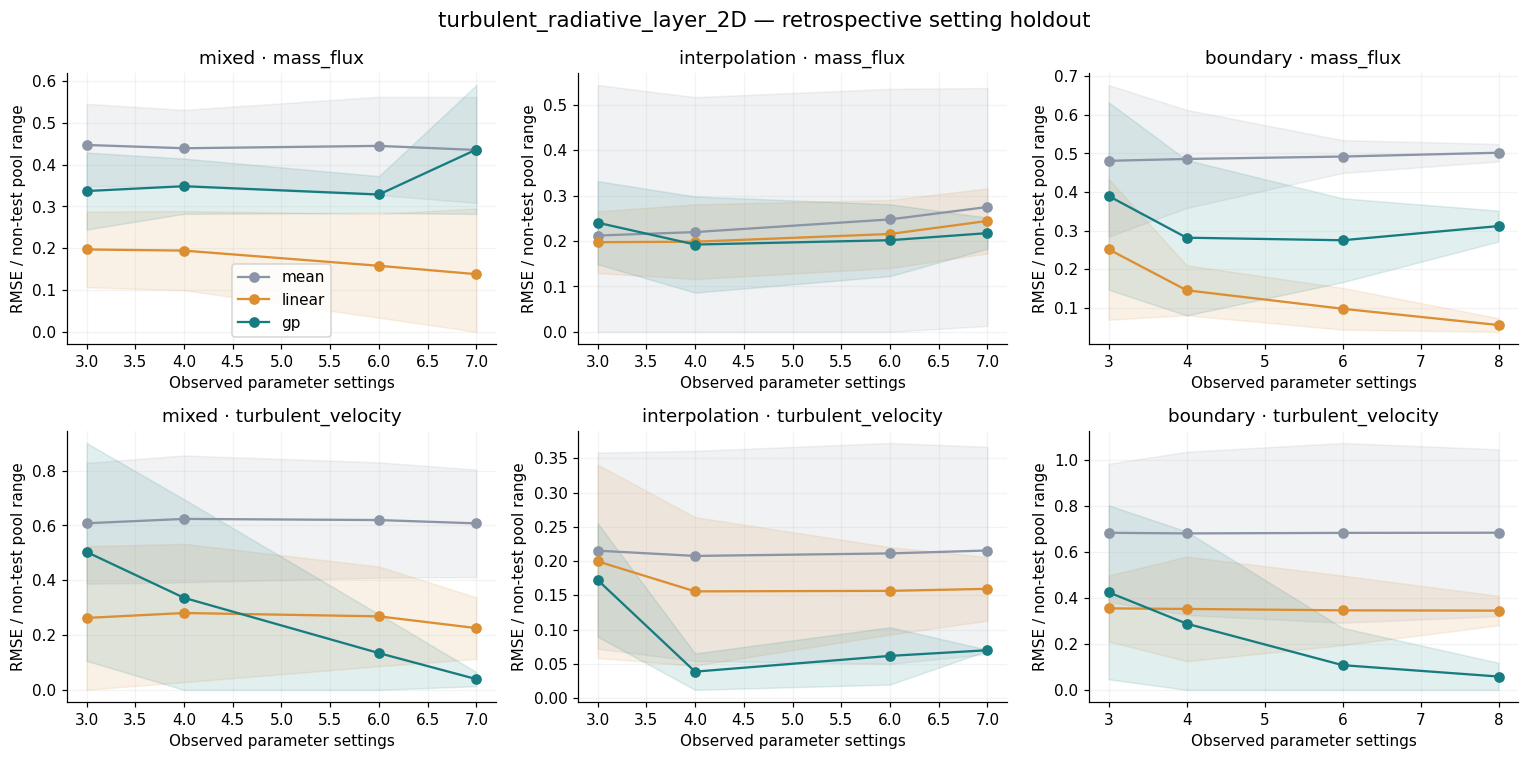

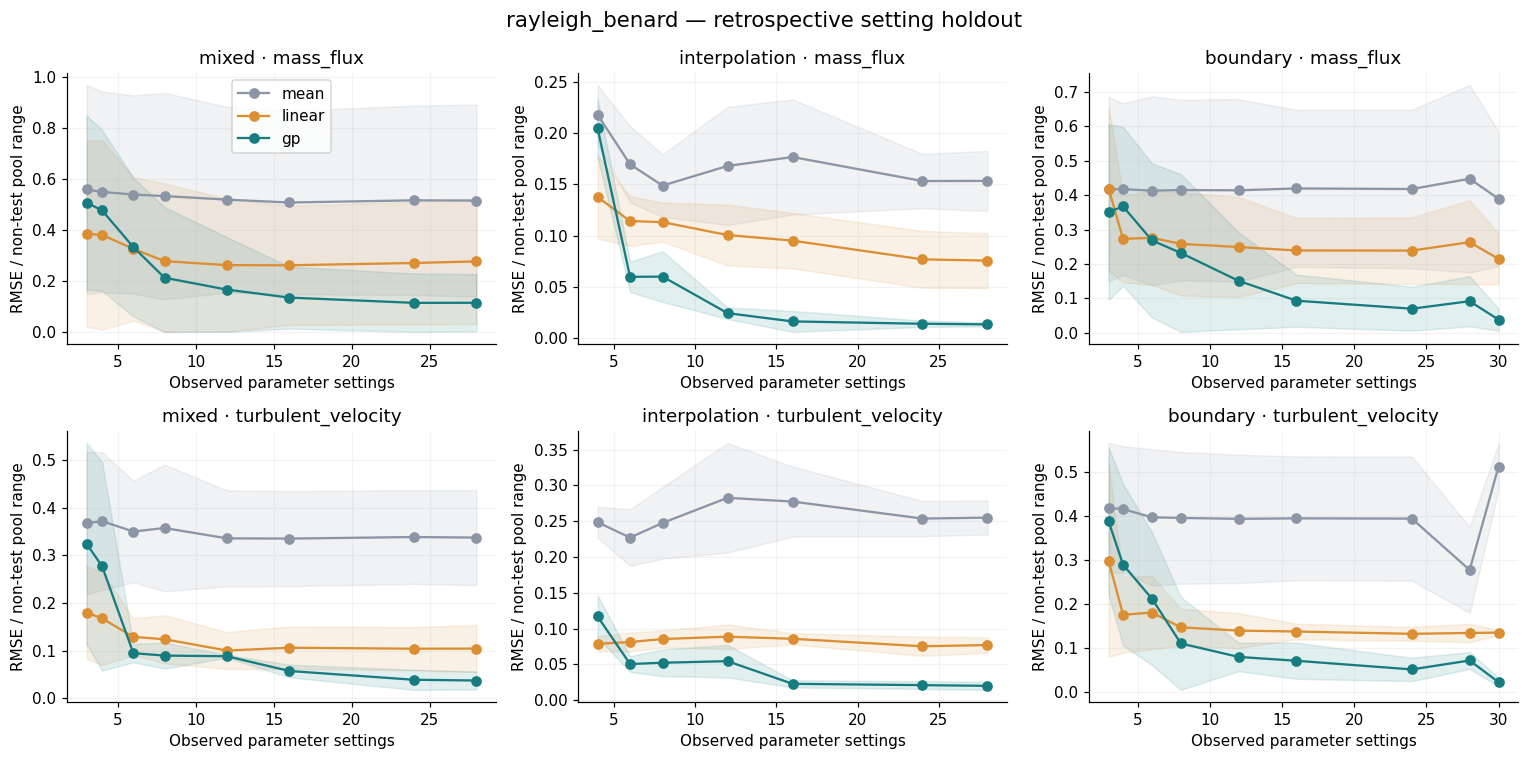

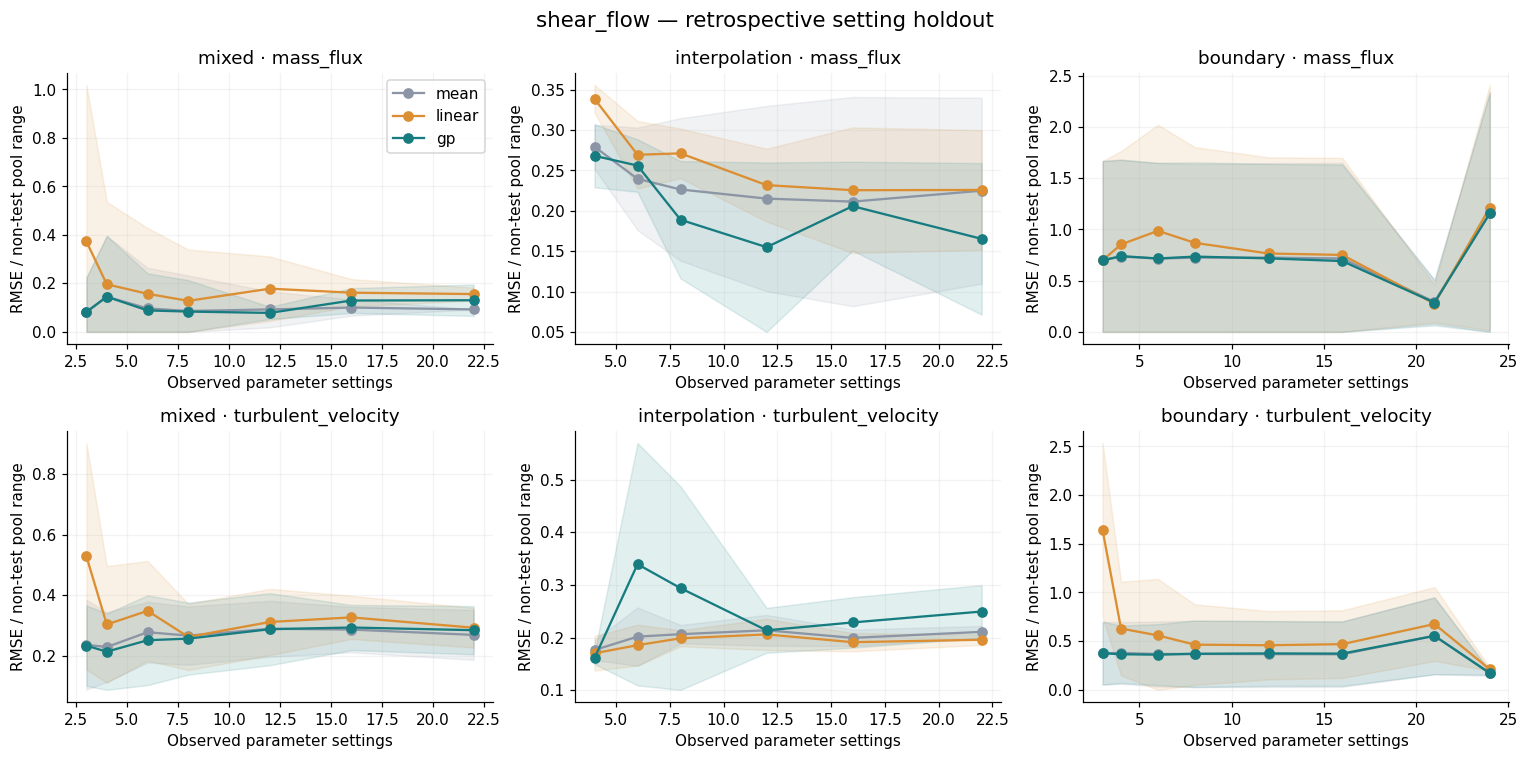

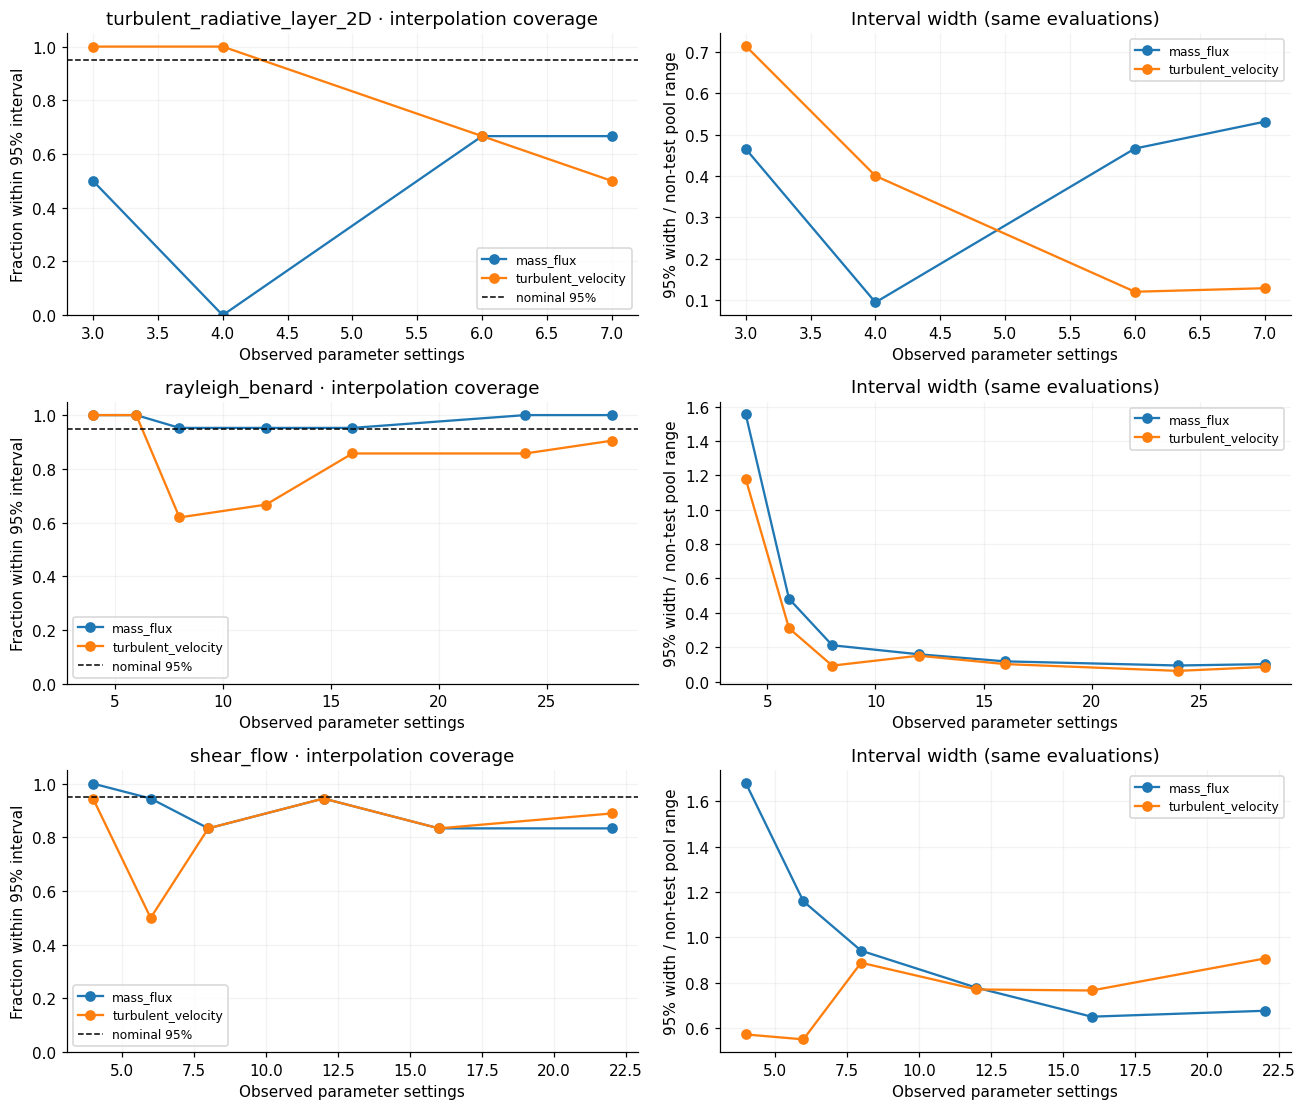

In [10]:
COLORS = {"mean": "#8b95a5", "linear": "#db8e32", "gp": "#177c80"}
for system in SYSTEMS:
    fig, axes = plt.subplots(2, 3, figsize=(14, 7), squeeze=False)
    for j, outcome in enumerate(OUTCOMES):
        for k, suite in enumerate(["mixed", "interpolation", "boundary"]):
            ax = axes[j,k]
            for method in PROTOCOL["models"]:
                part = summary.query("system == @system and outcome == @outcome and suite == @suite and method == @method")
                if part.empty: continue
                xx, yy = part.budget.to_numpy(), part.nrmse_mean.to_numpy()
                spread = part.nrmse_spread.fillna(0).to_numpy()
                ax.plot(xx, yy, "o-", color=COLORS[method], label=method)
                ax.fill_between(xx, np.maximum(yy-spread,0), yy+spread, color=COLORS[method], alpha=0.12)
            ax.set(title=f"{suite} · {outcome}", xlabel="Observed parameter settings", ylabel="RMSE / non-test pool range")
            ax.grid(alpha=0.15)
            if j==0 and k==0: ax.legend()
    fig.suptitle(f"{system} — retrospective setting holdout", fontsize=14)
    fig.tight_layout()
    fig.savefig(RUN_DIR / "figures" / f"{system}_learning_curves.png", dpi=160, bbox_inches="tight")
    plt.show(); plt.close(fig)

fig, axes = plt.subplots(len(SYSTEMS), 2, figsize=(12, 3.4*len(SYSTEMS)), squeeze=False)
for i, system in enumerate(SYSTEMS):
    for outcome in OUTCOMES:
        part = summary.query("system == @system and suite == 'interpolation' and method == 'gp' and outcome == @outcome")
        axes[i,0].plot(part.budget, part.coverage_95, "o-", label=outcome)
        axes[i,1].plot(part.budget, part.width_95_normalized, "o-", label=outcome)
    axes[i,0].axhline(.95, color="black", linestyle="--", linewidth=1, label="nominal 95%")
    axes[i,0].set(title=f"{system} · interpolation coverage", ylabel="Fraction within 95% interval", ylim=(0,1.05))
    axes[i,1].set(title="Interval width (same evaluations)", ylabel="95% width / non-test pool range")
    for ax in axes[i]:
        ax.set_xlabel("Observed parameter settings"); ax.grid(alpha=.15); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUN_DIR / "figures" / "gp_uncertainty.png", dpi=160, bbox_inches="tight")
plt.show(); plt.close(fig)

### 11 · Worked example: supply a few settings and predict the hidden ones
This example is selected **by protocol**, not by its score: cooling-time interpolation, first seed,
smallest budget. The observed training CSV and query CSV contain no hidden outcome labels. The separate
reference CSV is used only to show measured error after predicting. The example table and plot are real
held-out predictions already made in the benchmark, including any poor predictions.

Supplied: 3 aggregated settings. Predicted: 2 hidden settings.


,setting_id,t_cool,mass_flux,turbulent_velocity
0,turbulent_radiative_layer_2D:000,0.03,-0.035141,0.075538
8,turbulent_radiative_layer_2D:008,3.16,0.008215,0.040043
7,turbulent_radiative_layer_2D:007,1.78,-0.000241,0.040286


,setting_id,outcome,observed,predicted,lower_95,upper_95
56,turbulent_radiative_layer_2D:003,mass_flux,-0.007839,-0.027261,-0.050371,-0.004151
57,turbulent_radiative_layer_2D:004,mass_flux,-0.007656,-0.022271,-0.043556,-0.000986
58,turbulent_radiative_layer_2D:003,turbulent_velocity,0.050554,0.060041,0.043262,0.076819
59,turbulent_radiative_layer_2D:004,turbulent_velocity,0.045665,0.053325,0.037970,0.068680


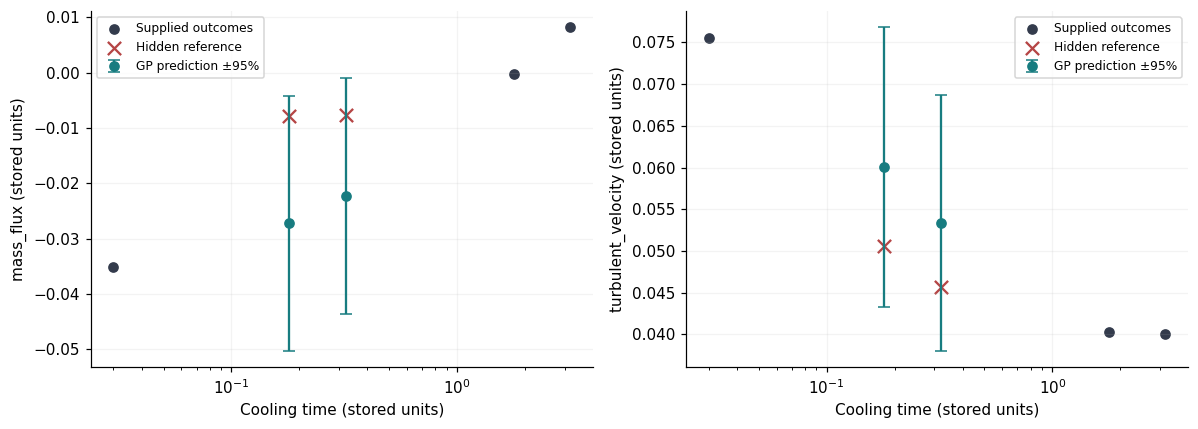

In [11]:
example_system = "turbulent_radiative_layer_2D"
example_split = next(s for s in SPLITS[example_system] if s["suite"]=="interpolation" and s["seed"]==SEEDS[0])
example_budget = example_split["budgets"][0]
t = tables[example_system]
observed = example_split["order"][:example_budget]
test = example_split["test"]
example = predictions[(predictions.system==example_system) & (predictions.split==example_split["split"]) &
                      (predictions.budget==example_budget) & (predictions.method=="gp")].copy()
example_cols = ["setting_id"] + INPUTS[example_system] + OUTCOMES
save_csv(t["frame"].iloc[observed][example_cols], RUN_DIR / "data" / "example_supplied_runs.csv")
save_csv(t["frame"].iloc[test][["setting_id"]+INPUTS[example_system]], RUN_DIR / "data" / "example_query_settings.csv")
save_csv(t["frame"].iloc[test][example_cols], RUN_DIR / "data" / "example_reference_outcomes.csv")
save_csv(example, RUN_DIR / "example_predictions.csv")
print(f"Supplied: {example_budget} aggregated settings. Predicted: {len(test)} hidden settings.")
display(t["frame"].iloc[observed][example_cols])
display(example[["setting_id","outcome","observed","predicted","lower_95","upper_95"]])
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for j, outcome in enumerate(OUTCOMES):
    part = example[example.outcome==outcome]
    ax = axes[j]
    ax.scatter(t["x"][observed,0], t["y"][observed,j], label="Supplied outcomes", color="#333b4c")
    ax.errorbar(t["x"][test,0], part.predicted, yerr=Z95*part.predictive_sd, fmt="o", capsize=4,
                label="GP prediction ±95%", color="#177c80")
    ax.scatter(t["x"][test,0], part.observed, marker="x", s=75, label="Hidden reference", color="#b54545")
    ax.set(xscale="log", xlabel="Cooling time (stored units)", ylabel=outcome+" (stored units)")
    ax.legend(fontsize=8); ax.grid(alpha=.15)
fig.tight_layout()
fig.savefig(RUN_DIR / "figures" / "worked_example.png", dpi=160, bbox_inches="tight")
plt.show(); plt.close(fig)

### 12 · Optional accuracy target and fair model comparison
If you set tolerances before running, we report both the first evaluated budget meeting them and whether
all later evaluated budgets also pass. Test scores are not a deployable stopping signal. No “runs saved”
is calculated: obtaining these historical test labels itself required simulations, and the source tables
do not tell us how many solver runs produced each setting mean.

In [12]:
targets = []
if ACCURACY_TOLERANCES:
    for (system,suite,split,method), part in metrics.groupby(["system","suite","split","method"]):
        if system not in ACCURACY_TOLERANCES: continue
        passing = part.groupby("budget").meets_tolerance.all().sort_index()
        first = next((int(b) for b, passed in passing.items() if passed), None)
        sustained = next((int(b) for b in passing.index if passing.loc[b:].all()), None)
        targets.append({"system":system,"suite":suite,"split":split,"method":method,
                        "first_observed_budget_meeting_target":first,
                        "first_budget_with_all_later_evaluated_budgets_passing":sustained,
                        "interpretation":"retrospective; not validated stopping or solver-run savings"})
save_json(RUN_DIR / "target_analysis.json", {"enabled":bool(ACCURACY_TOLERANCES), "results":targets})
if not targets:
    print("No engineering tolerance supplied: target achievement and run savings are not claimed.")

# Paired comparisons use identical training sets and test points, retaining each field separately.
paired = metrics.pivot(index=["system","suite","split","budget","outcome"], columns="method", values="rmse").reset_index()
paired["gp_better_than_mean"] = paired.gp < paired["mean"]
paired["gp_better_than_linear"] = paired.gp < paired.linear
save_csv(paired, RUN_DIR / "paired_comparisons.csv")
comparison = paired.groupby(["system","suite","outcome"], as_index=False).agg(
    comparisons=("gp","count"), gp_better_than_mean=("gp_better_than_mean","sum"),
    gp_better_than_linear=("gp_better_than_linear","sum"))
display(comparison)
save_csv(comparison, RUN_DIR / "comparison_summary.csv")

No engineering tolerance supplied: target achievement and run savings are not claimed.


,system,suite,outcome,comparisons,gp_better_than_mean,gp_better_than_linear
0,rayleigh_benard,boundary,mass_flux,96,89,70
1,rayleigh_benard,boundary,turbulent_velocity,96,91,67
2,rayleigh_benard,interpolation,mass_flux,21,21,19
3,rayleigh_benard,interpolation,turbulent_velocity,21,21,18
4,rayleigh_benard,mixed,mass_flux,24,23,16
5,rayleigh_benard,mixed,turbulent_velocity,24,23,16
6,shear_flow,boundary,mass_flux,84,27,68
7,shear_flow,boundary,turbulent_velocity,84,24,74
8,shear_flow,interpolation,mass_flux,18,13,13
9,shear_flow,interpolation,turbulent_velocity,18,7,5


### 13 · Final checks, report, and export
Completion means the declared pilot ran and its evidence is reproducible. It does **not** mean customer
utility, physical-unit provenance, trajectory lineage, or Delta‑V transfer-based savings were established.
The report keeps these open items visible so the next task can make an informed decision.

In [13]:
# Repeat the predeclared worked example from scratch and compare with saved predictions.
repeat, repeat_sd, _ = fit_predict(t["x"][observed], t["y"][observed], t["x"][test], "gp", SEEDS[0])
for j, outcome in enumerate(OUTCOMES):
    part = example[example.outcome==outcome]
    check(f"measured {outcome}: repeated prediction matches", np.allclose(repeat[:,j], part.predicted, rtol=1e-10, atol=0))
    check(f"measured {outcome}: repeated uncertainty matches", np.allclose(repeat_sd[:,j], part.predictive_sd, rtol=1e-10, atol=0))
check("protocol unchanged after evaluation", digest(json.dumps(PROTOCOL,sort_keys=True,allow_nan=False).encode())==PROTOCOL_HASH)
expected_fits = sum(len(s["budgets"])*len(PROTOCOL["models"]) for specs in SPLITS.values() for s in specs)
check("all planned fits completed", len(fit_rows)==expected_fits)
check("all interpolation queries lie within observed hull", predictions.loc[predictions.suite=="interpolation","inside_training_hull"].all())
check("all boundary queries lie outside observed hull", (~predictions.loc[predictions.suite=="boundary","inside_training_hull"]).all())
check("all evaluated errors finite", np.isfinite(metrics[["mae","rmse"]]).all().all())
save_json(RUN_DIR / "checks.json", checks)

lines = ["# Delta-V task 4 — measured pilot report", "",
    f"Protocol SHA-256: `{PROTOCOL_HASH}`", f"HF revision: `{HF_REVISION}`", "",
    f"Completed {len(fit_rows)} model fits and {len(predictions)} held-out scalar predictions in {benchmark_seconds:.1f} seconds.",
    f"All {len(checks)} correctness checks passed.", "",
    "## Data and scope", "",
    "Each row is an aggregated parameter setting, not an individual solver run. Systems were fitted separately.",
    "The mean and linear models are fair references for the GP; no pretrained neural model was tested.", ""]
for row in audit_rows:
    lines.append(f"- {row['system']}: {row['distinct_settings']} distinct settings, {row['input_dimensions']} inputs, two outcomes.")
lines += ["", "## Predeclared worked example", "",
          f"Cooling-time system, {example_budget} observed settings, {len(test)} held-out settings, interpolation seed {SEEDS[0]}."]
example_metrics = metrics[(metrics.system==example_system) & (metrics.split==example_split["split"]) &
                          (metrics.budget==example_budget) & (metrics.method=="gp")]
for r in example_metrics.to_dict("records"):
    lines.append(f"- {r['outcome']}: RMSE {r['rmse']:.6g} stored units; NRMSE {r['nrmse_pool_range']:.4f}; 95% coverage {r['coverage_95']:.1%}.")
lines += ["", "## Paired comparisons", "",
          "Counts below are descriptive field/budget/split comparisons with overlapping data, not independent statistical trials."]
for r in comparison.to_dict("records"):
    lines.append(f"- {r['system']} / {r['suite']} / {r['outcome']}: GP lower RMSE than mean in {r['gp_better_than_mean']}/{r['comparisons']}; than linear in {r['gp_better_than_linear']}/{r['comparisons']}.")
lines += ["", "## Uncertainty", "",
    "Inspect coverage together with interval width, by system and outcome. No calibrated uncertainty guarantee is made.",
    f"{sum(bool(r['warnings']) for r in fit_rows)} fits produced optimizer warnings; all are recorded in fit_details.json.",
    "GP intervals include fitted residual noise for aggregate table outcomes; raw-run variability and hyperparameter uncertainty are not fully represented.",
    "", "## Source expansion audit", ""]
for r in expansion_rows:
    lines.append(f"- {r['system']}: {r['distinct_filename_settings']} distinct filename settings, {r['additional_settings']} not in the table. {r['interpretation']}.")
lines += ["", "## What this completes", "",
    "Versioned table exports, integrity/schema audit, grouped setting splits, GP and simple baselines, scarce-data curves, boundary tests, coverage/width measurements, a measured example, and reproducible artifacts.",
    "", "## Evidence still needed", "",
    "- Confirm the original extraction lineage, window counts, physical units, field mapping and aggregation variability from raw sources.",
    "- Validate a real customer tolerance on a suitable engineering problem. No default acceptance threshold was invented.",
    "- Compare a later Delta-V learned predictor against this GP before attributing an advantage to transfer learning.",
    "- Test an end-to-end run-selection workflow and count all solver/validation costs before claiming savings.",
    "", "## Reproduction", "",
    "Run the notebook from a fresh kernel with its recorded controls. Tables and source inventories are embedded and hash-verified.",
    "Exact split membership and all model settings are in protocol.json. Version differences and timing variation may affect numerical reproduction.",
    "NRMSE uses the fixed non-test pool range for retrospective scoring only. No test or unacquired outcome labels enter fitting or training-order selection.",
    "Test outcomes have now been inspected: changing the protocol creates further exploratory analysis, not a new untouched test set."]
report = "\n".join(lines) + "\n"
(RUN_DIR / "REPORT.md").write_text(report)
save_json(RUN_DIR / "completion.json", {
    "status": "task4_aggregated_setting_pilot_complete", "checks_passed": len(checks),
    "protocol_sha256": PROTOCOL_HASH, "individual_run_dataset_verified": False,
    "customer_utility_validated": False, "transfer_based_run_savings_demonstrated": False,
    "result_files": ["metrics.csv", "predictions.csv", "summary.csv", "REPORT.md"],
})
manifest = {str(p.relative_to(RUN_DIR)): digest(p.read_bytes()) for p in sorted(RUN_DIR.rglob("*")) if p.is_file()}
save_json(RUN_DIR / "artifact_manifest.json", manifest)
archive = Path(shutil.make_archive(str(RUN_DIR), "zip", root_dir=RUN_DIR))
display(Markdown(report))
print("Saved results:", RUN_DIR.resolve())
display(FileLink(str(archive)))

# Delta-V task 4 — measured pilot report

Protocol SHA-256: `0e2c6e3829b0cbdcbf9943f475503fc9882b8310af1bb8a7f6d71b395c3cc84b`
HF revision: `e25651ff92cf1d8f8818164a0277b8613e83d8b3`

Completed 936 model fits and 9954 held-out scalar predictions in 5.5 seconds.
All 137 correctness checks passed.

## Data and scope

Each row is an aggregated parameter setting, not an individual solver run. Systems were fitted separately.
The mean and linear models are fair references for the GP; no pretrained neural model was tested.

- turbulent_radiative_layer_2D: 9 distinct settings, 1 inputs, two outcomes.
- rayleigh_benard: 35 distinct settings, 2 inputs, two outcomes.
- shear_flow: 28 distinct settings, 2 inputs, two outcomes.

## Predeclared worked example

Cooling-time system, 3 observed settings, 2 held-out settings, interpolation seed 42.
- mass_flux: RMSE 0.0171875 stored units; NRMSE 0.3287; 95% coverage 100.0%.
- turbulent_velocity: RMSE 0.00862206 stored units; NRMSE 0.2429; 95% coverage 100.0%.

## Paired comparisons

Counts below are descriptive field/budget/split comparisons with overlapping data, not independent statistical trials.
- rayleigh_benard / boundary / mass_flux: GP lower RMSE than mean in 89/96; than linear in 70/96.
- rayleigh_benard / boundary / turbulent_velocity: GP lower RMSE than mean in 91/96; than linear in 67/96.
- rayleigh_benard / interpolation / mass_flux: GP lower RMSE than mean in 21/21; than linear in 19/21.
- rayleigh_benard / interpolation / turbulent_velocity: GP lower RMSE than mean in 21/21; than linear in 18/21.
- rayleigh_benard / mixed / mass_flux: GP lower RMSE than mean in 23/24; than linear in 16/24.
- rayleigh_benard / mixed / turbulent_velocity: GP lower RMSE than mean in 23/24; than linear in 16/24.
- shear_flow / boundary / mass_flux: GP lower RMSE than mean in 27/84; than linear in 68/84.
- shear_flow / boundary / turbulent_velocity: GP lower RMSE than mean in 24/84; than linear in 74/84.
- shear_flow / interpolation / mass_flux: GP lower RMSE than mean in 13/18; than linear in 13/18.
- shear_flow / interpolation / turbulent_velocity: GP lower RMSE than mean in 7/18; than linear in 5/18.
- shear_flow / mixed / mass_flux: GP lower RMSE than mean in 8/21; than linear in 11/21.
- shear_flow / mixed / turbulent_velocity: GP lower RMSE than mean in 12/21; than linear in 17/21.
- turbulent_radiative_layer_2D / boundary / mass_flux: GP lower RMSE than mean in 22/24; than linear in 5/24.
- turbulent_radiative_layer_2D / boundary / turbulent_velocity: GP lower RMSE than mean in 24/24; than linear in 19/24.
- turbulent_radiative_layer_2D / interpolation / mass_flux: GP lower RMSE than mean in 4/12; than linear in 8/12.
- turbulent_radiative_layer_2D / interpolation / turbulent_velocity: GP lower RMSE than mean in 10/12; than linear in 10/12.
- turbulent_radiative_layer_2D / mixed / mass_flux: GP lower RMSE than mean in 9/12; than linear in 4/12.
- turbulent_radiative_layer_2D / mixed / turbulent_velocity: GP lower RMSE than mean in 12/12; than linear in 7/12.

## Uncertainty

Inspect coverage together with interval width, by system and outcome. No calibrated uncertainty guarantee is made.
171 fits produced optimizer warnings; all are recorded in fit_details.json.
GP intervals include fitted residual noise for aggregate table outcomes; raw-run variability and hyperparameter uncertainty are not fully represented.

## Source expansion audit

- turbulent_radiative_layer_2D: 9 distinct filename settings, 0 not in the table. No extra settings found; raw fields could improve repeat/aggregation audit.
- rayleigh_benard: 35 distinct filename settings, 0 not in the table. No extra settings found; raw fields could improve repeat/aggregation audit.
- shear_flow: 28 distinct filename settings, 0 not in the table. No extra settings found; raw fields could improve repeat/aggregation audit.

## What this completes

Versioned table exports, integrity/schema audit, grouped setting splits, GP and simple baselines, scarce-data curves, boundary tests, coverage/width measurements, a measured example, and reproducible artifacts.

## Evidence still needed

- Confirm the original extraction lineage, window counts, physical units, field mapping and aggregation variability from raw sources.
- Validate a real customer tolerance on a suitable engineering problem. No default acceptance threshold was invented.
- Compare a later Delta-V learned predictor against this GP before attributing an advantage to transfer learning.
- Test an end-to-end run-selection workflow and count all solver/validation costs before claiming savings.

## Reproduction

Run the notebook from a fresh kernel with its recorded controls. Tables and source inventories are embedded and hash-verified.
Exact split membership and all model settings are in protocol.json. Version differences and timing variation may affect numerical reproduction.
NRMSE uses the fixed non-test pool range for retrospective scoring only. No test or unacquired outcome labels enter fitting or training-order selection.
Test outcomes have now been inspected: changing the protocol creates further exploratory analysis, not a new untouched test set.


Saved results: ./delta_v_task4_results/20261015T171126_203958Z


./delta_v_task4_results/20261015T171126_203958Z.zip